# Notebook 05: One real measurement with SWSPy

**Goal (about 2.5 hours, can be split over two sessions: sections 1 to 6, then sections 7 to 9 and the exercises):** run the research pipeline's measurement on one real earthquake, reproduce to the digit the row Michael reported for it, see what changes when STAR's exchanged vertical and north channels are put the right way round, and then open the measurement up: the ray geometry it assumes, the 49 windows SWSPy tries, how it turns 49 answers into one, and what its quality score and error bars do and do not say.

By the end you should be able to explain, for this earthquake:

- why the archived and the corrected measurements differ;
- why the corrected one is east-west at the stored incidence angle and north-north-east at almost any other;
- what every panel of SWSPy's diagnostic plot shows, and what Q_w and the formal errors measure.

The library is SWSPy (Hudson, Asplet & Walker, 2023, *Seismica*; code at [github.com/TomSHudson/swspy](https://github.com/TomSHudson/swspy), MIT licence). The repo carries a local copy with small modifications made for the Axial Seamount and Rainier projects. The wrapper you call is `rainier_sws.measure.measure_event`; open it side by side with this notebook, it is about 80 lines and mirrors `process_event` in the research repo's `run_sws_generic.py`. Notebook 04 built the splitting measurement on synthetic data; this lesson assumes it. Words in **bold** are defined where they first appear; section 10 collects them in a glossary.

In [1]:
# --- setup: make the repo importable and keep figures inline ---
import sys
from pathlib import Path
REPO = Path.cwd().parent if (Path.cwd() / "../rainier_sws").exists() else Path.cwd()
sys.path.insert(0, str(REPO))
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
from rainier_sws import paths, data, measure, quality, stats
print("repo:", REPO)

repo: /Users/mhemmett/Seismology/rainier-sws-tutorials


## 1. The target

Event 61504668 at STAR is the example in Michael's figure 3. His pipeline reported:

In [2]:
ref = pd.read_csv(paths.station_results_csv("STAR"))
target = ref[ref.evid == 61504668].iloc[0]
target[["stage", "back_azimuth", "rectilinearity", "incidence_angle_jurkevics", "incidence_angle", "snr_horizontal",
        "filter_band", "phi", "dt", "phi_error", "dt_error", "quality", "dominant_period", "pct_anisotropy"]]

stage                                 ok
back_azimuth                   89.217446
rectilinearity                  0.834067
incidence_angle_jurkevics      45.687378
incidence_angle                29.026402
snr_horizontal                  8.504563
filter_band                  (5.0, 10.0)
phi                           -88.782554
dt                                  0.02
phi_error                            4.0
dt_error                            0.01
quality                              1.0
dominant_period                 0.107413
pct_anisotropy                  1.056812
Name: 33, dtype: object

What the columns are (the ones not yet defined are explained further down):

| column | meaning | where |
| --- | --- | --- |
| `stage` | how far the pipeline got: `ok`, or the name of the check that stopped it | section 2 |
| `back_azimuth` | direction from the station to the epicentre, degrees clockwise from north | notebook 02 |
| `rectilinearity` | how close the P-wave motion is to a straight line (1: a line) | section 5 |
| `incidence_angle_jurkevics`, `incidence_angle` | angle of the incoming ray from vertical: from the P-wave motion, and from ray tracing | section 5 |
| `snr_horizontal`, `filter_band`, `dominant_period` | the filter bank's S-wave SNR, its chosen band, and the S wave's dominant period | notebook 03 |
| `phi`, `dt` | fast direction (degrees from north, in (-90, 90]) and delay time (s) | notebooks 03 and 04 |
| `phi_error`, `dt_error` | formal errors of phi and dt | section 8 |
| `quality` | Q_w, SWSPy's quality score, from -1 to 1 | section 8 |
| `pct_anisotropy` | **percent anisotropy**, 100 dt / (S travel time along the ray, here 1.89 s) | notebook 04 |

Two incidence angles are listed. `incidence_angle_jurkevics` (45.7 deg) is estimated from the P-wave particle motion in the data; `incidence_angle` (29.0 deg) is from 3-D ray tracing through a velocity model and is the one the pipeline used. The ray tracer is not included in this repo, so **we pass the stored ray-traced angle in**. Notice already that the two estimates disagree by 17 degrees, and that the pipeline's 45-degree gate would have *rejected* this event on the Jurkevics angle. Hold on to that. (This Jurkevics angle was computed on the archived components, with the north record standing in for the vertical; on the corrected components of section 4 it is 71 degrees, further still from the ray-traced 29. Section 5 looks at why.)

## 2. Run the measurement

`measure.measure_event` does four things, in the research pipeline's order:

| step | what it does | sets | explained in |
| --- | --- | --- | --- |
| 1. geometry | back azimuth from the catalog locations; rectilinearity and Jurkevics angle from the first 0.12 s of P | `back_azimuth`, `rectilinearity`, `incidence_angle_jurkevics` | section 5 |
| 2. filter bank | filters the three components in 14 bands and keeps the one with the best S-wave SNR | `filter_band`, `snr_horizontal` | notebook 03 |
| 3. pre-processing gates | clip fraction, rectilinearity, incidence angle, SNR (`quality.PreGates`), in that order | `stage` | notebook 03; section 5 |
| 4. SWSPy | rotates the waveforms into the ray's frame, measures splitting in 49 windows, picks one answer, scores it | `phi`, `dt`, their errors, `quality` | sections 7 to 9 |

The first measurement of a session takes a few seconds longer than the rest: SWSPy's grid search is compiled to machine code (by numba) the first time it runs.

In [3]:
cat = data.load_station_catalog("STAR")
row = cat[cat.evid == 61504668].iloc[0]
# Michael's results were computed before STAR's exchanged Z and N were found (notebook 02), so to
# reproduce them we need the components as archived. Section 4 redoes the measurement corrected.
ev_archived = data.get_event_stream("STAR", row, allow_download=False, correct_orientation=False)
lat, lon, _ = data.station_coords("STAR")

m = measure.measure_event(row, ev_archived, "STAR", lat, lon, incidence_angle=target.incidence_angle)
mine = pd.Series(m.as_row())
mine[["stage", "back_azimuth", "rectilinearity", "incidence_angle_jurkevics", "snr_horizontal", "filter_band",
      "phi", "dt", "phi_error", "dt_error", "quality", "dominant_period"]]

stage                                 ok
back_azimuth                   89.217446
rectilinearity                  0.834067
incidence_angle_jurkevics      45.687378
snr_horizontal                  8.504563
filter_band                  (5.0, 10.0)
phi                           -88.782554
dt                                  0.02
phi_error                            4.0
dt_error                            0.01
quality                              1.0
dominant_period                 0.107413
dtype: object

In [4]:
compare = pd.DataFrame({"Michael": target, "this notebook": mine}).loc[
    ["back_azimuth", "rectilinearity", "snr_horizontal", "filter_band", "phi", "dt", "phi_error", "dt_error", "quality", "dominant_period"]]
compare["match"] = [np.isclose(float(a), float(b), atol=1e-6) if isinstance(a, (int, float, np.floating)) else a == b
                    for a, b in zip(compare.Michael, compare["this notebook"])]
compare

,Michael,this notebook,match
back_azimuth,89.217446,89.217446,True
rectilinearity,0.834067,0.834067,True
snr_horizontal,8.504563,8.504563,True
filter_band,"(5.0, 10.0)","(5.0, 10.0)",True
phi,-88.782554,-88.782554,True
dt,0.02,0.02,True
phi_error,4.0,4.0,True
dt_error,0.01,0.01,True
quality,1.0,1.0,True
dominant_period,0.107413,0.107413,True


If every row says `True`, you have reproduced a published-quality measurement from raw data. Write the date, your package versions (notebook 00) and this table in your lab notebook: that is your first replicability record.

This event reproduces in every number, but not every event does. Re-measuring all 709 of Michael's successful STAR rows in this environment (on the archived components; exercise 1 does it in about two minutes) reproduces 642 in every number; 53, about one in thirteen, differ in Q_w alone, and 14 in phi or dt as well (4 of those are not measured at all here). Those differences move 8 events across the post-processing cut, 2 out and 6 in, so the archived filtered set comes out as 114 events here instead of 110. The cause is the ill-conditioning described in the README: Q_w, and occasionally the whole answer, can tip on floating-point details. Section 7 shows a fast direction decided by a tie between two windows, one way that can happen.

If something does not match, the first suspects are: a different numpy/scipy version changing a floating-point tie-break, a different `filter_band` chosen because the SNR of two bands was nearly equal, or a different incidence angle passed in. Chase it down before continuing; it is the most instructive bug you will meet.

## 3. What the numbers mean

phi is reported as degrees from north in (-90, 90]. -88.8 is the same axis as 91.2: an east-west fast direction. dt is 0.02 s, the smallest non-zero delay SWSPy reports at 100 Hz (it reports dt in steps of 0.02 s; notebook 03, section 8, and section 7 below); the dominant period is 0.107 s, so dt is well under the half-period cycle-skip limit. Q_w is 1.0: SWSPy's two methods, eigenvalue and cross-correlation, give the same answer. phi_error (4 degrees) and dt_error (0.01 s) are **formal errors**: error bars computed from the shape of the misfit surface, not from repeating the measurement. 0.01 s is the smallest dt_error SWSPy can produce (section 8), so here it says more about the grid than about this event.

In [5]:
print(f"phi folded to [0,180): {measure.phi_0_180(m.phi):.1f} deg;  back azimuth {m.back_azimuth:.1f} deg;"
      f"  angle between fast axis and back azimuth: {stats.axial_diff(m.phi, m.back_azimuth):.1f} deg")

phi folded to [0,180): 91.2 deg;  back azimuth 89.2 deg;  angle between fast axis and back azimuth: 2.0 deg


Pause on that last number. The fast axis is within 2 degrees of the back azimuth. That is not by itself the geometry of a **null** (notebook 04): an S wave that arrives unsplit because it was already shaking along the fast axis or across it, so phi lines up with its **source polarization**, the direction the S wave shook the ground before it split. For a local earthquake that direction is set by the earthquake's focal mechanism, not by the back azimuth (SWSPy estimates it as `src_pol`, after undoing the split). But a fast axis that keeps lining up with the direction the waves come from is the warning sign of a measurement artifact rather than of the rock; notebook 07 screens the whole catalog for it (the **artifact check**), and exercise 4 compares the two screens. Hold on to this for section 4 too.

## 4. The components were the wrong way round

Everything above used STAR's channels as they are labelled in the archive, which is how the research results were computed. But at STAR the sensor labelled `EHZ` records north and the one labelled `EHN` records vertical motion (notebook 02). So the "horizontal" pair the measurement rotated and searched over was really the vertical and east records, with the north record standing in for the vertical in the LQT rotation. A fast direction measured that way is not the true one relabelled; it is a different measurement. Re-measure with the components corrected, everything else (incidence angle, parameters) the same:

In [6]:
ev = data.get_event_stream("STAR", row, allow_download=False)        # corrected: true Z, N, E
m_fixed = measure.measure_event(row, ev, "STAR", lat, lon, incidence_angle=target.incidence_angle)
cols = ["stage", "filter_band", "snr_horizontal", "phi", "dt", "phi_error", "dt_error", "quality", "dominant_period"]
both = pd.DataFrame({"as archived (Michael)": pd.Series(m.as_row())[cols], "corrected": pd.Series(m_fixed.as_row())[cols]})
both.loc["phi folded to [0, 180)"] = [measure.phi_0_180(m.phi), measure.phi_0_180(m_fixed.phi)]
both.loc["fast axis vs back azimuth (deg)"] = [stats.axial_diff(m.phi, m.back_azimuth), stats.axial_diff(m_fixed.phi, m_fixed.back_azimuth)]
both

,as archived (Michael),corrected
stage,ok,ok
filter_band,"(5.0, 10.0)","(5.0, 10.0)"
snr_horizontal,8.504563,13.995896
phi,-88.782554,-84.782554
dt,0.02,0.02
phi_error,4.0,11.0
dt_error,0.01,0.01
quality,1.0,-0.272074
dominant_period,0.107413,0.113231
"phi folded to [0, 180)",91.217446,95.217446


Same filter band, but the SNR goes from 8.5 to 14 (the archived "horizontal" SNR averaged in the vertical record, where S is weaker) and the dominant period moves a little (0.107 to 0.113 s). phi is 95 degrees instead of 91, still east-west and 6 degrees from the back azimuth, and dt is still 0.02 s, but phi_error grows from 4 to 11 degrees and Q_w drops from 1 to -0.27. Q_w compares the eigenvalue and cross-correlation methods; a negative value means they disagree in a way that, in the scheme of Wüstefeld et al. (2010), leans towards a null (section 8).

So, corrected, this event fails the post-processing filter (Q_w below 0.75), and the confident east-west measurement of section 3 becomes an unconfident one. The station as a whole changes much more: in the research pipeline's re-run on corrected components (`paths.station_results_csv("STAR", oriented=True)`, which notebook 07 uses), STAR's filtered set is 194 events instead of 110, with 44 in common, and most fast directions are north-north-east rather than east-west (README). The rest of this notebook uses the corrected data, and opens the measurement up to see where this event's answer comes from.

## 5. The ray at the station

Notebook 04 defines the geometry; here is a reminder, and what it looks like for this event.

- The **back azimuth** (notebook 02) is the direction from the station to the epicentre: 89 degrees here, so the waves come from the east.
- The **incidence angle** is the angle between the incoming ray and the vertical (notebook 03, section 3). Rays bend towards the vertical as they climb into slower rock near the surface, so they arrive steeper than a straight line from the earthquake would.
- The **shear-wave window** (notebook 04): an S wave that reaches the surface steeper than the **critical angle**, arcsin(Vs / Vp), about 35 degrees for Vp / Vs = 1.73, is recorded with its shape intact; beyond it the free surface converts part of it into other waves and shifts its phase, which can fake or hide a split (Booth & Crampin, 1985). The pipeline's gate is 45 degrees (`quality.PreGates.incidence_max_deg`), the usual allowance for slow rock just below the station bending rays more steeply than the velocity model knows.
- **LQT** (notebook 04): the three components rotated into the ray's own frame. **L** points along the ray, which is the way a P wave shakes; **Q** is across the ray in the vertical plane that contains it; **T** (transverse) is horizontal and across the ray. An S wave shakes across its ray, so it lives on Q and T, and SWSPy measures splitting in the Q-T plane. It measures the fast direction from Q first (**phi from Q**, `phi_Q`) and then turns it into degrees from north by adding the back azimuth: phi = back azimuth + phi_Q, for this event 89.2 + 6 = 95.2, section 4's answer.

The incidence angle is used twice, by the gate and by the rotation, and it comes from two places that disagree. Here are both for every STAR event (corrected components):

median: ray-traced 27 deg, Jurkevics 61 deg; above the 45-degree gate: 6% and 86%


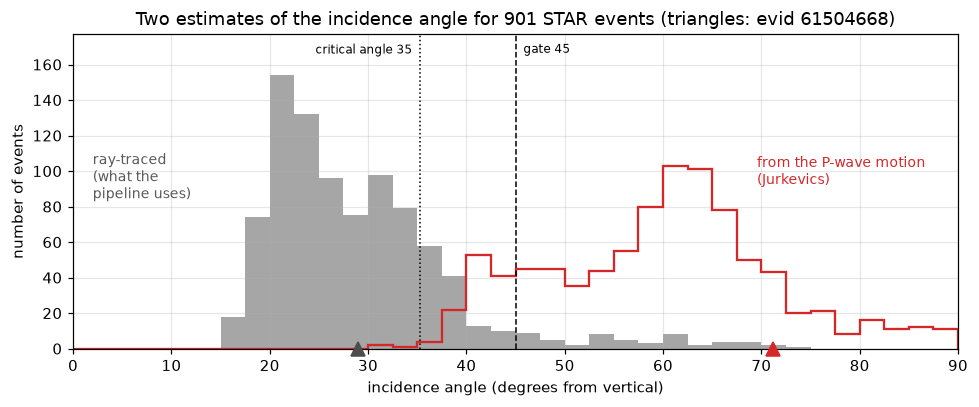

In [7]:
res_o = pd.read_csv(paths.station_results_csv("STAR", oriented=True))   # the research re-run on corrected components
gate = quality.DEFAULT_PRE.incidence_max_deg
VP_VS = 1.73                      # Vp / Vs of the velocity model behind the ray tracing (README)
critical = np.degrees(np.arcsin(1 / VP_VS))
angles = res_o.dropna(subset=["incidence_angle", "incidence_angle_jurkevics"])

fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.arange(0, 92.5, 2.5)
n_ray, _, _ = ax.hist(angles.incidence_angle, bins, color="0.65")
n_jur, _, _ = ax.hist(angles.incidence_angle_jurkevics, bins, histtype="step", color="tab:red", lw=1.5)
top = 1.15 * max(n_ray.max(), n_jur.max())
ax.set_ylim(0, top)
for x, ls, name, ha, dx in [(critical, ":", f"critical angle {critical:.0f}", "right", -0.8), (gate, "--", f"gate {gate:.0f}", "left", 0.8)]:
    ax.axvline(x, color="k", ls=ls, lw=1)
    ax.text(x + dx, top * 0.97, name, fontsize=8, va="top", ha=ha)
ax.text(2, n_ray.max() * 0.55, "ray-traced\n(what the\npipeline uses)", ha="left", fontsize=9, color="0.35")
ax.text(angles.incidence_angle_jurkevics.median() + 9, n_jur.max() * 0.9, "from the P-wave motion\n(Jurkevics)", fontsize=9, color="tab:red")
for x, c in [(target.incidence_angle, "0.3"), (m_fixed.incidence_angle_jurkevics, "tab:red")]:
    ax.plot(x, 0, "^", color=c, ms=9, clip_on=False, zorder=5)
ax.set(xlabel="incidence angle (degrees from vertical)", ylabel="number of events", xlim=(0, 90),
       title=f"Two estimates of the incidence angle for {len(angles)} STAR events (triangles: evid 61504668)")
plt.tight_layout()
print(f"median: ray-traced {angles.incidence_angle.median():.0f} deg, Jurkevics {angles.incidence_angle_jurkevics.median():.0f} deg; "
      f"above the {gate:.0f}-degree gate: {(angles.incidence_angle > gate).mean():.0%} and {(angles.incidence_angle_jurkevics > gate).mean():.0%}")

The ray tracer puts STAR's rays at 27 degrees from vertical (median), comfortably inside the window, and only 6 percent of the events beyond the gate. The P-wave motion says 61 degrees, and on it 86 percent of the events would fail the gate. These cannot both describe the same rays, and the README lists the difference as unexplained. To see what the P-wave estimate measures, look at the P wave.

### P polarization and rectilinearity

A P wave shakes the ground along its ray, so the direction of the P-wave motion should point back along the ray. The pipeline measures that direction with the method of **Jurkevics (1988)**: take the first 0.12 s of P (from 0.02 s before the pick) on all three components, form their 3 x 3 **covariance matrix** (how much each pair of components varies together), and find its eigenvectors and eigenvalues λ1 ≥ λ2 ≥ λ3. The eigenvector of λ1 is the direction of strongest motion; its angle from vertical is the Jurkevics incidence angle. The eigenvalues also say how straight the motion is: the **rectilinearity**, 1 - (λ2 + λ3) / (2 λ1), is 1 for motion along a line and 0 for motion spread equally in all directions. The pipeline requires at least 0.5 (`PreGates.rectilinearity_min`): a check that the P wave looks like a P wave.

The figure shows the P wave on Z, R and T, where **R** (radial) is horizontal and points away from the epicentre and T is across it, and then its **particle motion** (the path the ground follows, one component against another) in the vertical plane that contains the ray, and seen from above. Grey dashed lines: where the motion would point if it followed the ray (the ray-traced angle, and the back azimuth); red: the direction the eigenvectors find.

P window: 13 samples, 0.12 s starting 0.02 s before the pick; eigenvalues [1.    0.305 0.027] x the largest
rectilinearity 0.834 (pipeline 0.834); P motion 71.2 deg from vertical (pipeline 71.2); its horizontal direction 138 deg; back azimuth 89 deg


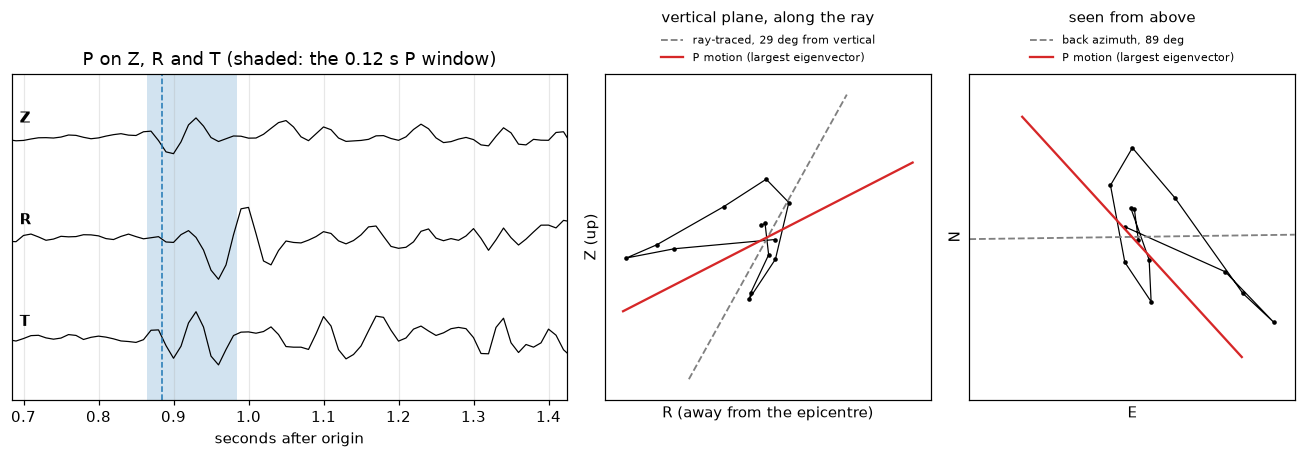

In [8]:
import inspect
from rainier_sws import sws_functions as swsf
jw = inspect.signature(swsf.calculate_incidence_angle_eigenvalue_jurkevics).parameters      # the pipeline's P window
p_before, p_len = jw["p_window_before"].default, jw["analysis_window"].default
origin, p_time, s_time, p_off, s_off = measure.pick_offsets(ev, row)
zne = ev.copy().detrend("demean")
w0 = p_time - p_before                                   # start of the P window
X = np.column_stack([zne.select(channel=f"??{c}")[0].slice(w0, w0 + p_len).data for c in "ZNE"]).astype(float)
lam, vec = swsf.cov_eig(X)                               # eigenvalues largest first; vec[:, 0] = direction of the P motion
p_dir = vec[:, 0] * np.sign(vec[0, 0])                   # (Z, N, E), pointing up
rect = 1 - (lam[1] + lam[2]) / (2 * lam[0])
p_inc = np.degrees(np.arccos(abs(p_dir[0])))
p_az = np.degrees(np.arctan2(p_dir[2], p_dir[1])) % 180
print(f"P window: {len(X)} samples, {p_len} s starting {p_before} s before the pick; eigenvalues {np.round(lam / lam[0], 3)} x the largest")
print(f"rectilinearity {rect:.3f} (pipeline {m_fixed.rectilinearity:.3f}); P motion {p_inc:.1f} deg from vertical "
      f"(pipeline {m_fixed.incidence_angle_jurkevics:.1f}); its horizontal direction {p_az:.0f} deg; back azimuth {m_fixed.back_azimuth:.0f} deg")

rt = zne.copy().rotate("NE->RT", back_azimuth=m_fixed.back_azimuth)       # R: horizontal, pointing away from the epicentre
seg = {c: rt.select(channel=f"??{c}")[0].slice(w0, w0 + p_len).data for c in "ZRT"}
seg.update({c: zne.select(channel=f"??{c}")[0].slice(w0, w0 + p_len).data for c in "NE"})
baz = np.radians(m_fixed.back_azimuth)
p_R = -p_dir[2] * np.sin(baz) - p_dir[1] * np.cos(baz)    # the P direction in the same R (ObsPy's convention)
i_ray = np.radians(target.incidence_angle)

fig = plt.figure(figsize=(12, 3.9))
gs = fig.add_gridspec(1, 3, width_ratios=[1.7, 1, 1])
ax0 = fig.add_subplot(gs[0])
scale = 1.2 * max(np.abs(seg[c]).max() for c in "ZRT")
for k, c in enumerate("ZRT"):
    tr = rt.select(channel=f"??{c}")[0]
    ax0.plot(tr.times(reftime=origin), tr.data / scale - 2 * k, "k", lw=0.8)
    ax0.text(p_time - origin - 0.19, -2 * k + 0.25, c, fontweight="bold")
ax0.axvspan(w0 - origin, w0 + p_len - origin, color="tab:blue", alpha=0.2, lw=0)
ax0.axvline(p_time - origin, color="tab:blue", ls="--", lw=1)
ax0.set(xlim=(p_time - origin - 0.2, s_time - origin - 0.05), ylim=(-5.2, 1.2), yticks=[], xlabel="seconds after origin",
        title="P on Z, R and T (shaded: the 0.12 s P window)")
ax1, ax2 = fig.add_subplot(gs[1]), fig.add_subplot(gs[2])
for ax, (x, y), (dx_ray, dy_ray), (dx_p, dy_p), (xl, yl), ray_label in [
        (ax1, (seg["R"], seg["Z"]), (np.sin(i_ray), np.cos(i_ray)), (p_R, p_dir[0]), ("R (away from the epicentre)", "Z (up)"),
         f"ray-traced, {target.incidence_angle:.0f} deg from vertical"),
        (ax2, (seg["E"], seg["N"]), (np.sin(baz), np.cos(baz)), (p_dir[2], p_dir[1]), ("E", "N"),
         f"back azimuth, {m_fixed.back_azimuth:.0f} deg")]:
    A = 1.15 * np.abs(np.r_[x, y]).max()
    ax.plot(x, y, "k.-", lw=0.8, ms=4)
    ax.plot([-A * dx_ray, A * dx_ray], [-A * dy_ray, A * dy_ray], color="0.5", ls="--", lw=1.2, label=ray_label)
    u = np.hypot(dx_p, dy_p)
    ax.plot([-A * dx_p / u, A * dx_p / u], [-A * dy_p / u, A * dy_p / u], color="tab:red", lw=1.5, label="P motion (largest eigenvector)")
    ax.set(xlim=(-A, A), ylim=(-A, A), aspect="equal", xlabel=xl, ylabel=yl, xticks=[], yticks=[])
    ax.legend(frameon=False, fontsize=7.5, loc="lower center", bbox_to_anchor=(0.5, 1.0))
ax1.set_title("vertical plane, along the ray", pad=34, fontsize=10)
ax2.set_title("seen from above", pad=34, fontsize=10)
plt.tight_layout()

The P motion passes the gate easily (rectilinearity 0.83), but it is a flattened ellipse rather than a line (λ2 is 30 percent of λ1), and it does not point back along the ray: it is 71 degrees from vertical against the ray tracer's 29, and, seen from above, it points 138 degrees from north against a back azimuth of 89, 48 degrees off. So it is not just a wrong incidence angle: in its first 0.12 s this P wave does not shake along any ray from the catalog location.

Part of a difference like this is expected. At the free surface the reflected waves add to the incoming P, and the ground moves along an *apparent* angle of about 2 arcsin((Vs / Vp) sin i) from vertical (Svenningsen & Jacobsen, 2007): 33 degrees for a ray at 29 degrees and Vp / Vs = 1.73. That is 4 degrees, not 42. Other candidates are not tested here: STAR sits on a steep flank of the volcano (topography bends and scatters waves), the window holds only 13 samples, about one cycle at 10 Hz, so a little scattered energy right after P counts as much as the direct wave, and the location itself has an error. This lesson uses the ray-traced angle, as the pipeline does; exercise 3 asks how much the answer depends on it.

### LQT: what the rotation does

Rotate the three components into L, Q and T (ObsPy's `Stream.rotate("ZNE->LQT", back_azimuth, inclination)`) with the ray-traced angle and with the Jurkevics angle. If the angle and the back azimuth were exactly right and the waves clean, P would sit entirely on L and S only on Q and T. Blue: the P window of the Jurkevics measurement; red: the span of SWSPy's analysis windows around S (section 7). The table gives the share of each window's energy (sum of squares) on each component.

,P energy on L,P energy on Q,P energy on T,S energy on L,S energy on Q,S energy on T
"ray-traced, 29 deg",0.29,0.35,0.35,0.18,0.34,0.47
"Jurkevics, 71 deg",0.50,0.15,0.35,0.41,0.12,0.47


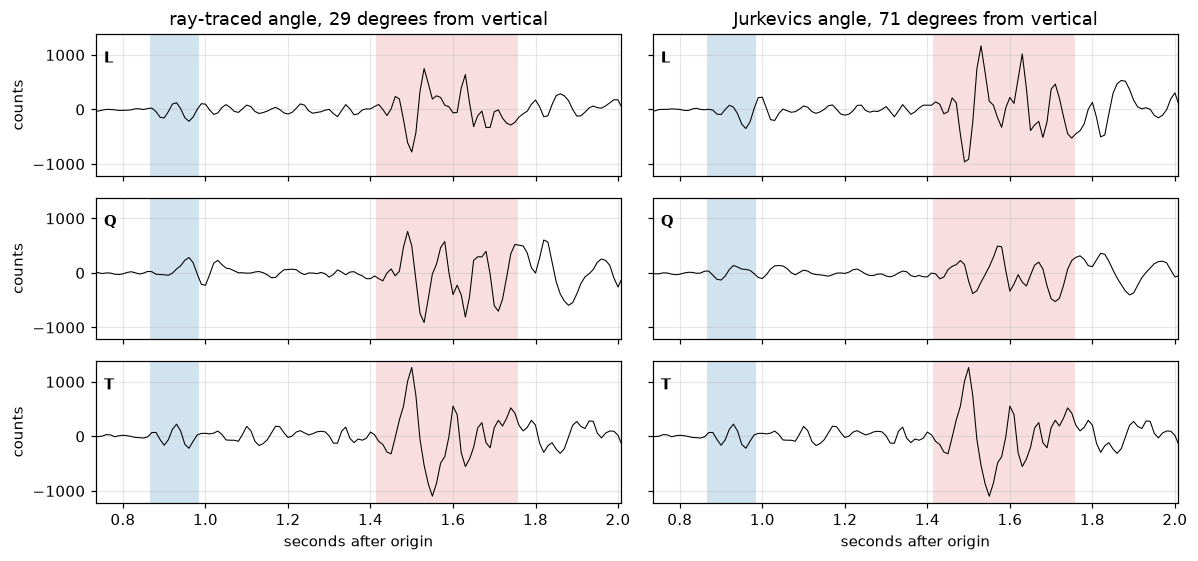

In [9]:
so = m_fixed.splitting_object
s_from = s_time - so.overall_win_start_pre_fast_S_pick         # the span SWSPy's analysis windows cover (section 7)
s_to = s_time + so.overall_win_end_post_fast_S_pick
share = {}
fig, axes = plt.subplots(3, 2, figsize=(11, 5.2), sharex=True, sharey=True)
for j, (name, inc) in enumerate({"ray-traced": target.incidence_angle, "Jurkevics": m_fixed.incidence_angle_jurkevics}.items()):
    lqt = zne.copy().rotate("ZNE->LQT", back_azimuth=m_fixed.back_azimuth, inclination=inc)
    for i, c in enumerate("LQT"):
        tr = lqt.select(channel=f"??{c}")[0]
        ax = axes[i, j]
        ax.plot(tr.times(reftime=origin), tr.data, "k", lw=0.7)
        ax.axvspan(w0 - origin, w0 + p_len - origin, color="tab:blue", alpha=0.2, lw=0)
        ax.axvspan(s_from - origin, s_to - origin, color="tab:red", alpha=0.15, lw=0)
        ax.text(0.015, 0.8, c, transform=ax.transAxes, fontweight="bold")
    energy = {w: {c: float(np.sum(lqt.select(channel=f"??{c}")[0].slice(t0, t1).data.astype(float) ** 2)) for c in "LQT"}
              for w, (t0, t1) in {"P": (w0, w0 + p_len), "S": (s_from, s_to)}.items()}
    share[f"{name}, {inc:.0f} deg"] = {f"{w} energy on {c}": energy[w][c] / sum(energy[w].values()) for w in "PS" for c in "LQT"}
    axes[0, j].set_title(f"{name} angle, {inc:.0f} degrees from vertical")
    axes[-1, j].set_xlabel("seconds after origin")
axes[0, 0].set_xlim(p_time - origin - 0.15, s_to - origin + 0.25)
for ax in axes[:, 0]:
    ax.set_ylabel("counts")
plt.tight_layout()
pd.DataFrame(share).T.round(2)

Neither angle separates the two waves cleanly:

- At the **ray-traced** angle (29 degrees) the S window keeps 81 percent of its energy on Q and T, which is what the splitting measurement reads, but the P wave is spread over all three components, with only 29 percent on L and 35 percent on Q.
- At the **Jurkevics** angle (71 degrees) half of P lands on L, but 41 percent of the S-window energy moves onto L, where SWSPy never looks.
- At either angle a large part of P is on T, because its horizontal motion is 48 degrees off the back azimuth, and no choice of incidence angle can fix a back-azimuth mismatch.

SWSPy's windows start 0.03 to 0.06 s before the S pick, so the P coda leaking onto Q and T just before S is part of what it measures. The incidence angle is therefore not just a gate: it decides which mixture of P coda and S the measurement sees. The next section shows how much that matters for this event.

## 6. The same event with a different incidence angle

Rerun with a few angles around the stored ray-traced one, up to the gate (`PreGates.incidence_max_deg`), and with the Jurkevics angle of section 5.

In [10]:
rows = []
for inc in [15, 25, target.incidence_angle, 35, gate, m_fixed.incidence_angle_jurkevics]:
    mm = measure.measure_event(row, ev, "STAR", lat, lon, incidence_angle=inc)
    rows.append({"incidence_used": round(inc, 1), "stage": mm.stage, "phi": mm.phi, "phi in [0, 180)": measure.phi_0_180(mm.phi),
                 "dt": mm.dt, "phi_error": mm.phi_error, "dt_error": mm.dt_error, "Q_w": mm.quality})
pd.DataFrame(rows).round(3)

,incidence_used,stage,phi,"phi in [0, 180)",dt,phi_error,dt_error,Q_w
0,15.0,ok,37.217,37.217,0.02,11.0,0.01,0.906
1,25.0,ok,35.217,35.217,0.02,11.0,0.01,0.906
2,29.0,ok,-84.783,95.217,0.02,11.0,0.01,-0.272
3,35.0,ok,31.217,31.217,0.02,11.0,0.01,0.497
4,45.0,ok,25.217,25.217,0.02,10.0,0.01,0.937
5,71.2,fail_incidence,NaN,NaN,NaN,NaN,NaN,NaN


On the corrected data this event is not stable. dt stays at 0.02 s, but phi is 25 to 37 degrees (north-north-east) at every angle except the stored ray-traced one, 29 degrees, which gives 95 (east-west), and Q_w ranges from -0.27 to 0.94: at 15, 25 and 45 degrees this event would pass the Q_w cut. At the Jurkevics angle the gate stops the event, as it would stop most STAR events (section 5).

The gate's behaviour is the known reason PANH, OBSR, PARA, RER and COPP have (near) zero measurements in the research results: with the ray-traced angles, essentially none of their swarm events fall inside the 45-degree shear-wave window. So the question for those stations is not "is the measurement wrong" but "is the gate right, and how sensitive is everything to the velocity model behind the angle". That is a threshold question, and notebook 07 is about thresholds.

Hold on to the puzzle in the table: why would 4 degrees of rotation turn the fast direction by 60 degrees? Section 7 answers it.

## 7. What SWSPy does: windows, a grid, two methods and a choice

Notebook 04 built the core of the measurement: rotate into a trial fast direction, shift the slow component back by a trial delay, and keep the (phi, dt) that makes the particle motion most linear. SWSPy does that many times over:

1. it cuts 49 **analysis windows** around the S pick, each a different guess of where S starts and ends;
2. in each window it runs a **grid search** over (phi, dt) with two methods, so each window gives two answers;
3. it **clusters** the 49 answers of the main method and picks one;
4. it compares that answer with the other method's (Q_w, section 8).

### The windows

Run the measurement once more with `verbose=True`: `measure_event` normally hides what SWSPy prints.

In [11]:
m_verbose = measure.measure_event(row, ev, "STAR", lat, lon, incidence_angle=target.incidence_angle, verbose=True)

S-pick time relative to start of trace: 1.474395
Dominant period E-comp: 9.846153846153847
Dominant period N-comp: 12.8
Dominant period: 0.11323076923076923
First window start time before S-pick, in seconds: 0.06
Last window start time before S-pick, in seconds: 0.03
First window end time after S-pick, in seconds: 0.16984615384615384
Last window end time after S-pick, in seconds: 0.28307692307692306
Adjusted first window end time after S-pick, in seconds: 0.17
Adjusted last window end time after S-pick, in seconds: 0.28323076923076923
S-pick time in samples, relative to the trace start (where trace starts at the earliest window start time): 6
Start window index range in samples: 3
End window index range in samples: 11
First start window: 0
Last start window: 3
Full start window range: [0 0 1 1 2 2 3]
First end window: 23
Last end window: 34
Full end window range: [23 24 26 28 30 32 34]


Read it from the top:

- `S-pick time relative to start of trace: 1.474` is the S travel time: the S pick relative to the *origin* time. (The label is SWSPy's; the trace starts 5 s before the origin.)
- The dominant periods of E and N are in samples (9.8 and 12.8); their mean, 0.113 s, is **Tmid**, the dominant period used to size the windows (notebook 03, section 7).
- Windows **start** between 0.06 and 0.03 s before the S pick: `first_window_start` = 2 and `last_window_start` = 1, times `s_pick_uncertainty` = 0.03 s (`measure.SwsParams`). The comment in `SwsParams` says the window boundaries are "in units of dominant period"; for the starts that is wrong, they are in units of `s_pick_uncertainty`. Only the ends are in dominant periods.
- Windows **end** between `first_window_end` = 1.5 and `last_window_end` = 2.5 dominant periods after the pick (0.170 to 0.283 s), after one adjustment: the shortest window, from the latest start to the earliest end, must be at least `max_t_shift_s` = 0.2 s, the largest delay searched, because SWSPy applies a delay by wrapping the trace around inside the window. Here it was 0.1998 s, so the earliest end moves out by 0.15 ms: harmless.
- `n_win` = 7 starts times 7 ends gives 49 windows. The start indices, `[0 0 1 1 2 2 3]` samples from the beginning of SWSPy's cut, are 7 evenly spaced values over a range of 3 samples (0.03 s at 100 Hz), rounded down. So only 4 starts are different, and 21 of the 49 windows exactly repeat another one. That holds for every STAR event, because the start range is set by `s_pick_uncertainty` alone. The ends, `[23 24 26 28 30 32 34]`, are all different.

### The grid and the two methods

In each window SWSPy tries every trial fast direction from -90 to +90 degrees from Q in steps of 2 degrees (91 values) and 20 trial delays, 0 to 0.19 s. It applies a delay by shifting the fast component half of it one way and the slow component half of it the other, each by a whole number of samples rounded down. So trial delays of 0.00 and 0.01 s both shift nothing, 0.02 and 0.03 s both shift one sample each way, and so on: in effect it tests 10 delays, 0 to 0.18 s in steps of 0.02 s, and every second row of its grid repeats the one before (section 8 checks). That is where the 0.02 s steps of dt come from (notebook 03, section 8), and why 0.18 s is the largest dt in either STAR results file.

For each trial (phi, dt) it computes two scores on the corrected Q and T:

- **Eigenvalue method (EV)**, as in notebook 04: the ratio λ2 / λ1 of the eigenvalues of their 2 x 2 covariance matrix. Straight-line particle motion has λ2 = 0, so the best (phi, dt) is the minimum. (Rotating, and shifting by wrapping around, leave the total energy in the window, λ1 + λ2, unchanged, so minimising λ2 alone would find the same point; the ratio is easier to compare between events, because it does not depend on how loud the earthquake was.) This is the method of Silver & Chan (1991), and SWSPy's answer.
- **Cross-correlation method (XC)**: once the split is undone, the fast and slow waves should have the same shape, so SWSPy multiplies them sample by sample, averages the absolute values, divides by the product of their standard deviations, and takes the maximum. It is an independent check, used only for Q_w.

That is 49 windows x 91 directions x 20 delays, about 89,000 trial corrections per method, in a fraction of a second (exercise 6 times it).

### Recording the 49 answers

`measure_event` keeps SWSPy's final answer but not the 49 per-window answers. They all pass through one method, `_sws_win_clustering`, so we can record them on the way with a small wrapper, a **spy**: it calls the real method, notes what went in and what came out, and returns the result unchanged; the `with` block puts the original back afterwards. A spy observes the pipeline without changing it; if you need it often, the clean fix is for `measure.py` to keep the window answers itself.

In [12]:
from contextlib import contextmanager
from swspy.splitting import split_windowcheck

@contextmanager
def record_windows():
    """Inside a `with` block, record what SWSPy's window clustering receives and what it chooses.

    measure_event does not keep the per-window answers, so this wraps SWSPy's clustering method for the
    duration of the block (a "spy", in software-testing language) and puts the original back afterwards.
    Every measurement calls it twice: first with the eigenvalue answers, then with the cross-correlation ones.
    """
    calls = []
    cls = split_windowcheck.create_splitting_object
    original = cls._sws_win_clustering
    def spy(self, lags, phis, lag_errs, phi_errs, **kwargs):
        out = original(self, lags, phis, lag_errs, phi_errs, **kwargs)
        calls.append({"windows": pd.DataFrame({"dt": np.array(lags), "phi_Q": np.array(phis),
                                               "dt_err": np.array(lag_errs), "phi_err": np.array(phi_errs)}),
                      "phi_Q": out[0], "dt": out[1], "origin": self.origin_times[0]})
        return out
    cls._sws_win_clustering = spy
    try:
        yield calls
    finally:
        cls._sws_win_clustering = original

with record_windows() as calls:
    m_w = measure.measure_event(row, ev, "STAR", lat, lon, incidence_angle=target.incidence_angle)
so = m_w.splitting_object
fs = ev[0].stats.sampling_rate
p = measure.SwsParams()
idx = so.event_station_win_idxs["STAR"]
cut = -so.overall_win_start_pre_fast_S_pick              # SWSPy cuts the traces from here (s, relative to the S pick)
win = {}
for method, call in zip(["eigenvalue", "cross-correlation"], calls):
    w = call["windows"].copy()
    w["start"] = cut + np.repeat(idx["win_start_idxs"], p.n_win) / fs     # window k: start k // n_win, end k % n_win
    w["end"] = cut + np.tile(idx["win_end_idxs"], p.n_win) / fs
    w["phi_N"] = measure.phi_0_180(w.phi_Q + m_w.back_azimuth)
    win[method] = w
ev_w = win["eigenvalue"]
answer_N, xc_N = measure.phi_0_180(m_w.phi), measure.phi_0_180(calls[1]["phi_Q"] + m_w.back_azimuth)
print(f"{len(ev_w)} windows, {len(ev_w[['start', 'end']].drop_duplicates())} of them different; "
      f"starts {np.unique(ev_w.start.round(2))} s and ends {np.unique(ev_w.end.round(2))} s from the S pick")
print("eigenvalue method, dt of the windows:", ev_w.dt.value_counts().to_dict())
near_answer = stats.axial_diff(ev_w.phi_N, answer_N) <= 20
near_xc = stats.axial_diff(ev_w.phi_N, xc_N) <= 20
print(f"phi within 20 deg of the reported {answer_N:.0f}: {near_answer.sum()} windows; within 20 deg of the "
      f"cross-correlation answer {xc_N:.0f}: {near_xc.sum()}; neither: {(~near_answer & ~near_xc).sum()}")
ev_w.head(7)

49 windows, 28 of them different; starts [-0.06 -0.05 -0.04 -0.03] s and ends [0.17 0.18 0.2  0.22 0.24 0.26 0.28] s from the S pick
eigenvalue method, dt of the windows: {0.02: 48, 0.18: 1}
phi within 20 deg of the reported 95: 15 windows; within 20 deg of the cross-correlation answer 39: 33; neither: 1


,dt,phi_Q,dt_err,phi_err,start,end,phi_N
0,0.02,6.0,0.01,12.0,-0.06,0.17,95.217446
1,0.02,-4.0,0.01,41.0,-0.06,0.18,85.217446
2,0.02,-56.0,0.01,13.0,-0.06,0.20,33.217446
3,0.02,-6.0,0.01,41.0,-0.06,0.22,83.217446
4,0.02,-50.0,0.01,32.0,-0.06,0.24,39.217446
5,0.02,-54.0,0.01,29.0,-0.06,0.26,35.217446
6,0.02,-50.0,0.04,38.0,-0.06,0.28,39.217446


Each row is one window: where it starts and ends relative to the S pick, the EV answer (dt, phi from Q, phi from N) and its formal errors. The first seven rows share a start and differ in their end; rows 7 to 13 repeat them exactly.

The summary lines tell the story. 48 windows say dt = 0.02 s; one says 0.18 s, the largest delay on the grid. In fast direction they fall into two families: 15 windows give east-west (within 20 degrees of the reported 95) and 33 give north-north-east (within 20 degrees of 39, the cross-correlation answer). The reported answer comes from the *smaller* family.

### From 49 answers to one

SWSPy follows Teanby et al. (2004): find the windows that agree with each other, and report the best-constrained answer from the tightest group. Agreement is decided by **DBSCAN** (Ester et al., 1996), a clustering method that does not need to be told how many clusters there are. Each window's answer becomes a point in a plane in which the fast direction is doubled (so that -90 and +90 degrees, the same axis, meet) and the delay is the distance from the centre, scaled by the largest delay among the windows:

$$x = \frac{dt}{dt_{max}} \cos 2\phi_Q, \qquad y = \frac{dt}{dt_{max}} \sin 2\phi_Q .$$

A point with at least `cluster_min_samples` = 15 points (itself included) within a distance `cluster_eps` = 0.15 is a **core point**; core points within 0.15 of each other join one cluster, together with their neighbours; points in no cluster are **noise**. Then the **choice rule**:

1. among the clusters, take the one with the smallest variance: the larger of the scatter of its answers and the variance implied by their formal errors (Teanby et al., 2004, eqs. 13 and 14);
2. within it, report the window with the smallest phi_err² + dt_err². With phi in degrees and dt in seconds, that is in practice the window with the smallest phi_err; on a tie, the first such window in the list wins.

The cell below applies the rule to the recorded windows, then asks SWSPy's own clustering what it would choose if the single window at dt = 0.18 s were not there.

In [13]:
ci = so.clustering_info["STAR"]
members = ci["clusters_dict"][str(ci["min_var_idx"])]["sample_idxs"]
cost = ev_w.dt_err ** 2 + ev_w.phi_err ** 2                   # the choice rule inside the cluster (deg^2 + s^2)
chosen = cost.iloc[members].idxmin()                           # first window with the smallest cost
tied = cost.iloc[members][cost.iloc[members] == cost.iloc[members].min()].index
print(f"clusters found: {len(ci['clusters_dict'])}, with {[len(c['phis']) for c in ci['clusters_dict'].values()]} windows; "
      f"outside any cluster: {len(ev_w) - len(members)} (dt {ev_w.dt.drop(members).tolist()} s)")
print(f"phi_Q in the chosen cluster: {ev_w.phi_Q.iloc[members].min():.0f} to {ev_w.phi_Q.iloc[members].max():.0f} deg")
print(f"smallest phi_err in the cluster: {ev_w.phi_err.iloc[members].min():.0f} deg, shared by windows {list(tied)} "
      f"with phi_N {ev_w.phi_N[tied].round(1).tolist()}; SWSPy takes the first, window {chosen}: phi_N {ev_w.phi_N[chosen]:.1f}")

# What if the one window at dt = 0.18 s were not there? Ask SWSPy's own clustering.
keep = ev_w[ev_w.dt < ev_w.dt.max()]
alt_phi_Q, alt_dt, alt_phi_err, _, alt_clusters, alt_best, _ = so._sws_win_clustering(
    keep.dt.values, keep.phi_Q.values, keep.dt_err.values, keep.phi_err.values,
    eps=p.cluster_eps, min_samples=p.cluster_min_samples, return_clusters_data=True)
alt_members = keep.index[alt_clusters[str(alt_best)]["sample_idxs"]]
print(f"\nwithout it: {len(alt_clusters)} cluster(s) of {[len(c['phis']) for c in alt_clusters.values()]} windows; answer phi_N "
      f"{measure.phi_0_180(alt_phi_Q + m_w.back_azimuth):.1f}, dt {alt_dt} s, phi_err {alt_phi_err:.0f} deg")

clusters found: 1, with [48] windows; outside any cluster: 1 (dt [0.18] s)
phi_Q in the chosen cluster: -56 to 6 deg
smallest phi_err in the cluster: 11 deg, shared by windows [14, 21, 28, 35, 44] with phi_N [95.2, 95.2, 95.2, 95.2, 35.2]; SWSPy takes the first, window 14: phi_N 95.2

without it: 1 cluster(s) of [33] windows; answer phi_N 35.2, dt 0.02 s, phi_err 11 deg


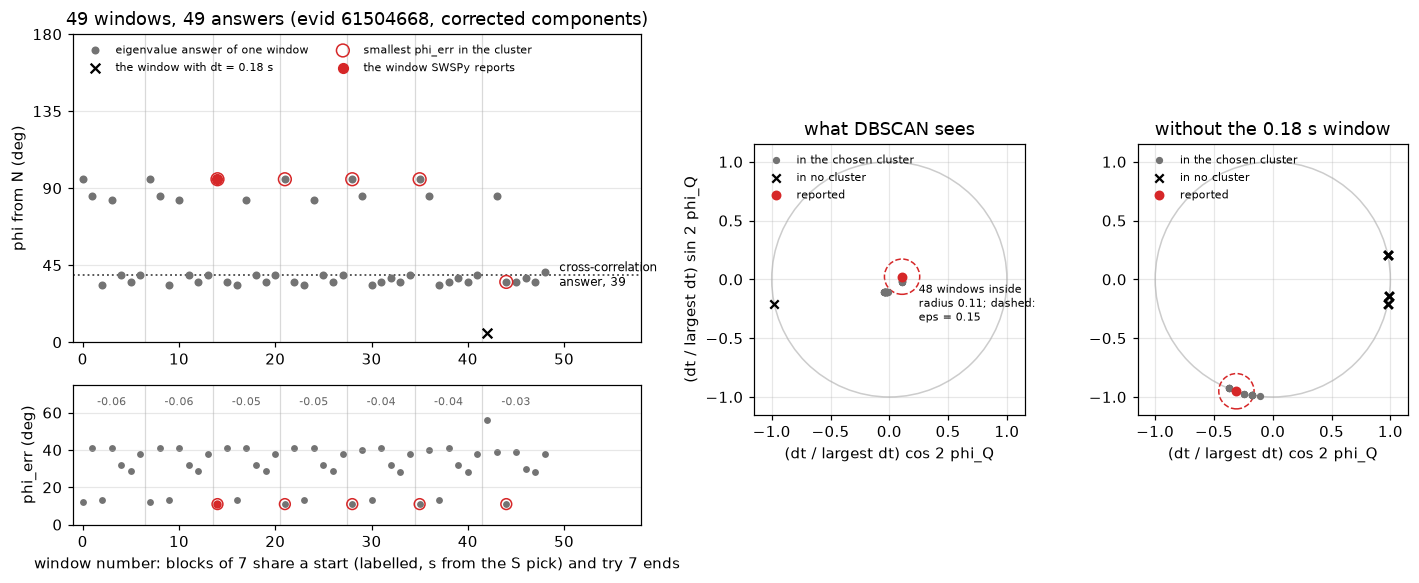

In [14]:
fig = plt.figure(figsize=(13, 5.4))
gs = fig.add_gridspec(2, 3, width_ratios=[2.1, 1, 1], height_ratios=[2.2, 1])
axA = fig.add_subplot(gs[0, 0]); axE = fig.add_subplot(gs[1, 0], sharex=axA)
axB = fig.add_subplot(gs[:, 1]); axC = fig.add_subplot(gs[:, 2], sharex=axB, sharey=axB)
k = np.arange(len(ev_w))
edge = ev_w.dt == ev_w.dt.max()
axA.scatter(k[~edge], ev_w.phi_N[~edge], s=18, color="0.45", zorder=3, label="eigenvalue answer of one window")
axA.scatter(k[edge], ev_w.phi_N[edge], s=40, marker="x", color="k", zorder=3, label=f"the window with dt = {ev_w.dt.max():.2f} s")
axA.scatter(k[tied], ev_w.phi_N[tied], s=70, facecolor="none", edgecolor="tab:red", zorder=4, label="smallest phi_err in the cluster")
axA.scatter(chosen, ev_w.phi_N[chosen], s=40, color="tab:red", zorder=5, label="the window SWSPy reports")
axA.axhline(xc_N, color="0.3", ls=":", lw=1.2); axA.text(len(ev_w) + 0.5, xc_N, f"cross-correlation\nanswer, {xc_N:.0f}", va="center", fontsize=8)
axA.set(ylim=(0, 180), yticks=[0, 45, 90, 135, 180], ylabel="phi from N (deg)", xlim=(-1, len(ev_w) + 9),
        title="49 windows, 49 answers (evid 61504668, corrected components)")
axA.legend(frameon=False, fontsize=7.5, loc="upper left", ncol=2)
axE.scatter(k, ev_w.phi_err, s=12, color="0.45")
axE.scatter(k[tied], ev_w.phi_err[tied], s=50, facecolor="none", edgecolor="tab:red")
axE.scatter(chosen, ev_w.phi_err[chosen], s=20, color="tab:red", zorder=5)
axE.set(ylabel="phi_err (deg)", ylim=(0, 75),
        xlabel="window number: blocks of 7 share a start (labelled, s from the S pick) and try 7 ends")
for ax in (axA, axE):
    for b in range(1, p.n_win):
        ax.axvline(b * p.n_win - 0.5, color="0.85", lw=0.8, zorder=0)
    ax.grid(axis="x", visible=False)
for b in range(p.n_win):
    axE.text(b * p.n_win + 3, 64, f"{ev_w.start.iloc[b * p.n_win]:+.2f}", ha="center", fontsize=7.5, color="0.4")

def plane(ax, w, members, pick, title):
    """The windows as DBSCAN sees them; red: the reported window, with a circle of radius eps around it."""
    r = w.dt / w.dt.max()
    x, y = r * np.cos(2 * np.radians(w.phi_Q)), r * np.sin(2 * np.radians(w.phi_Q))
    out = ~w.index.isin(members)
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="0.8", lw=1))
    ax.scatter(x[~out], y[~out], s=14, color="0.45", label="in the chosen cluster", zorder=3)
    ax.scatter(x[out], y[out], s=30, marker="x", color="k", label="in no cluster", zorder=3)
    ax.scatter(x[pick], y[pick], s=30, color="tab:red", zorder=4, label="reported")
    ax.add_patch(plt.Circle((x[pick], y[pick]), p.cluster_eps, fill=False, color="tab:red", ls="--", lw=1))
    ax.set(xlim=(-1.15, 1.15), ylim=(-1.15, 1.15), aspect="equal", title=title, xlabel="(dt / largest dt) cos 2 phi_Q")
    ax.legend(frameon=False, fontsize=7.5, loc="upper left")

alt_cost = cost.loc[alt_members]
plane(axB, ev_w, members, chosen, "what DBSCAN sees")
axB.set_ylabel("(dt / largest dt) sin 2 phi_Q")
plane(axC, keep, alt_members, alt_cost.idxmin(), f"without the {ev_w.dt.max():.2f} s window")
axB.text(0.25, -0.35, f"48 windows inside\nradius {ev_w.dt.min() / ev_w.dt.max():.2f}; dashed:\neps = {p.cluster_eps}", fontsize=7.5)
plt.tight_layout()

Read the figure from the left.

- **Two families, one cluster.** The 15 east-west windows and the 33 north-north-east ones all belong to one cluster. The middle panel shows why: the single window at dt = 0.18 s sets dt_max, so the other 48, at dt = 0.02 s, sit within radius 0.11 of the centre, where every point is within reach of an eps of 0.15. Fast directions 60 degrees apart are squeezed together because the delay is small, and the delay counts as small only relative to one window at the edge of the grid.
- **A tie decides the direction.** In that cluster the smallest phi_err, 11 degrees, is shared by four east-west windows and one north-north-east window (red circles). Their costs are exactly equal, so SWSPy takes the first in its list, window 14, an east-west one. The 95 degrees that the corrected measurement reports rests on the order in which SWSPy lists its windows.
- **Without the edge window** (right panel) SWSPy's own clustering separates the families: one cluster of the 33 north-north-east windows, the east-west ones left as noise, and the answer is 35 degrees from north (window 44, the north-north-east window of the tie) with the same dt and phi_err.

So for this event the fast direction is set by the window-selection rule, not by the data alone: the data offer two answers, and one window at the edge of the delay grid and a tie-break choose between them. Exercise 2 asks how often that happens across the station.

### Back to the puzzle of section 6

Record the windows at each incidence angle of section 6:

In [15]:
rows = []
for inc in [15, 25, target.incidence_angle, 35, gate]:
    with record_windows() as c:
        mm = measure.measure_event(row, ev, "STAR", lat, lon, incidence_angle=inc)
    w = c[0]["windows"]
    phi_N = measure.phi_0_180(mm.phi)
    rows.append({"incidence": round(inc, 1), "phi (from N)": round(phi_N, 1),
                 "windows within 20 deg of it": int((stats.axial_diff(w.phi_Q + mm.back_azimuth, phi_N) <= 20).sum()),
                 "largest window dt": w.dt.max(), "cross-correlation phi": round(measure.phi_0_180(c[1]["phi_Q"] + mm.back_azimuth), 1),
                 "Q_w": round(mm.quality, 2)})
pd.DataFrame(rows)

,incidence,phi (from N),windows within 20 deg of it,largest window dt,cross-correlation phi,Q_w
0,15.0,37.2,42,0.02,43.2,0.91
1,25.0,35.2,39,0.02,41.2,0.91
2,29.0,95.2,15,0.18,39.2,-0.27
3,35.0,31.2,29,0.02,63.2,0.50
4,45.0,25.2,28,0.02,29.2,0.94


At 15, 25, 35 and 45 degrees most windows (28 to 42 of the 49) agree with a north-north-east answer, no window reaches 0.18 s, and that is what SWSPy reports. Only at 29 degrees does one window land at the edge of the grid, merge the two families into one cluster, and hand the decision to the tie, which goes east-west. Four degrees of rotation did not turn the fast direction by 60 degrees; they changed which of two candidate answers the choice rule picked. The cross-correlation answer, which does not depend on that tie, stays between 29 and 43 degrees at four of the five angles (63 at 35 degrees, where only 29 EV windows agree and Q_w is 0.50).

## 8. Q_w and the formal errors

### Q_w: do the two methods agree?

Wüstefeld et al. (2010) proposed comparing the EV answer with the XC answer to sort automatic measurements without a human. For a good split both methods find the same answer; for a null they disagree in a characteristic way, with the XC fast direction about 45 degrees from the EV one and the XC delay near zero (Wüstefeld & Bokelmann, 2007). Two numbers measure the comparison: the delay ratio **rho** = dt_XC / dt_EV, and the angle difference phi_EV − phi_XC divided by 45 degrees. A good split sits at (rho, dphi / 45) = (1, 0) and a null at (0, 1). The distances from those two points, each divided by √2 (the distance between them) and capped at 1, are d_good and d_null, and

$$Q_w = \begin{cases} -(1 - d_{null}) & \text{if } d_{null} < d_{good} \\ 1 - d_{good} & \text{otherwise.} \end{cases}$$

So Q_w = 1 is a perfect split, -1 a perfect null, and values near 0 mean "neither". The pipeline keeps Q_w ≥ 0.75 (`PostFilter.qw_min`). The function below is the formula as SWSPy codes it (`_calc_Q_w`); first check that it reproduces this event's value from the two answers the spy recorded. Then, because STAR has a lot of Q_w values of exactly 0, the cell re-measures every corrected event with Q_w = 0 (about 20 s) to see where those come from.

eigenvalue: phi_Q 6, dt 0.02 s; cross-correlation: phi_Q -50, dt 0.02 s
rho = 1.00, dphi / 45 = 1.244: Q_w = -0.2721 (SWSPy: -0.2721)



re-measured 115 corrected events with Q_w = 0 (still 0 here: 108): XC delay placeholder 14; EV and XC within 20 deg as axes 23; other 78
archived: Q_w exactly 0 for 292 of 709; >= 0.75: 162
corrected: Q_w exactly 0 for 115 of 659; >= 0.75: 350


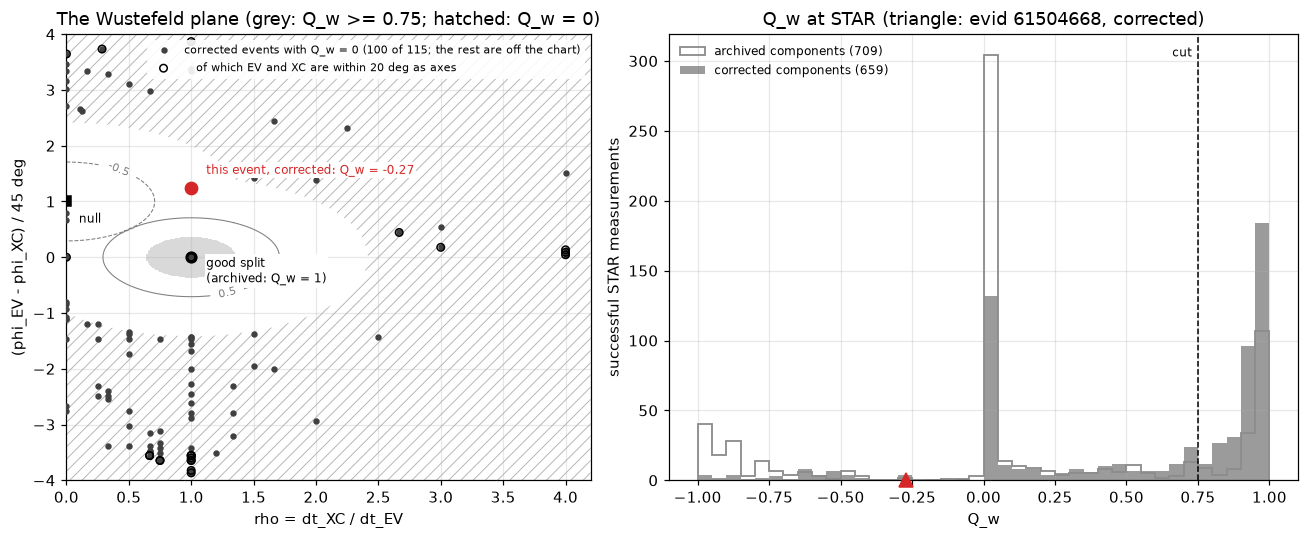

In [16]:
import gc
gc.freeze()   # SWSPy runs Python's garbage collector twice per measurement; skip the objects that exist now (exercise 6)

def q_w(rho, dphi_45):
    """Wustefeld et al. (2010) quality factor, as SWSPy's _calc_Q_w computes it.
    rho = dt_XC / dt_EV; dphi_45 = (phi_EV - phi_XC) / 45, both phi measured from Q."""
    d_null = np.minimum(np.sqrt((rho ** 2 + (dphi_45 - 1) ** 2) / 2), 1)
    d_good = np.minimum(np.sqrt(((rho - 1) ** 2 + dphi_45 ** 2) / 2), 1)
    return np.where(d_null < d_good, -(1 - d_null), 1 - d_good)

rho_ev = calls[1]["dt"] / calls[0]["dt"]
dphi_ev = (calls[0]["phi_Q"] - calls[1]["phi_Q"]) / 45
print(f"eigenvalue: phi_Q {calls[0]['phi_Q']:.0f}, dt {calls[0]['dt']} s; cross-correlation: phi_Q {calls[1]['phi_Q']:.0f}, dt {calls[1]['dt']} s")
print(f"rho = {rho_ev:.2f}, dphi / 45 = {dphi_ev:.3f}: Q_w = {float(q_w(rho_ev, dphi_ev)):.4f} (SWSPy: {m_w.quality:.4f})")

ok_o = quality.successful(res_o)
ok_a = quality.successful(ref)
zeros = ok_o[ok_o.quality == 0]
cat_by_evid = cat.set_index("evid")
pairs = []
with record_windows() as calls_0:
    for _, t in zeros.iterrows():
        r = cat_by_evid.loc[t.evid].copy(); r["evid"] = t.evid
        n_before = len(calls_0)
        mm = measure.measure_event(r, data.get_event_stream("STAR", r, allow_download=False), "STAR", lat, lon,
                                   incidence_angle=t.incidence_angle)
        ev_c, xc_c = calls_0[n_before], calls_0[n_before + 1]
        pairs.append({"evid": t.evid, "Q_w": mm.quality, "rho": xc_c["dt"] / ev_c["dt"], "dphi_45": (ev_c["phi_Q"] - xc_c["phi_Q"]) / 45,
                      "axial difference": float(stats.axial_diff(ev_c["phi_Q"], xc_c["phi_Q"]))})
pairs = pd.DataFrame(pairs)
placeholder = pairs.rho > 100
axially_close = ~placeholder & (pairs["axial difference"] <= 20)
print(f"\nre-measured {len(pairs)} corrected events with Q_w = 0 (still 0 here: {(pairs.Q_w == 0).sum()}): "
      f"XC delay placeholder {placeholder.sum()}; EV and XC within 20 deg as axes {axially_close.sum()}; other {(~placeholder & ~axially_close).sum()}")

x_max = 4.2
rr, dd = np.meshgrid(np.linspace(0, x_max, 421), np.linspace(-4, 4, 801))
Q = q_w(rr, dd)
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1, 1.2]})
ax0.contourf(rr, dd, (Q >= quality.DEFAULT_POST.qw_min).astype(float), levels=[0.5, 1.5], colors=["0.85"])
with plt.rc_context({"hatch.color": "0.7", "hatch.linewidth": 0.6}):
    ax0.contourf(rr, dd, (Q == 0).astype(float), levels=[0.5, 1.5], hatches=["///"], colors="none")
cs = ax0.contour(rr, dd, Q, levels=[-0.5, 0.5], colors="0.5", linewidths=0.7)
ax0.clabel(cs, fontsize=7, fmt="%.1f")
shown = pairs[~placeholder & (pairs.rho <= x_max)]
ax0.scatter(shown.rho, shown.dphi_45, s=10, color="0.25", zorder=3,
            label=f"corrected events with Q_w = 0 ({len(shown)} of {len(pairs)}; the rest are off the chart)")
ax0.scatter(shown.rho[axially_close], shown.dphi_45[axially_close], s=24, facecolor="none", edgecolor="k", zorder=3,
            label="   of which EV and XC are within 20 deg as axes")
box = dict(fc="w", ec="none", pad=1)
ax0.plot(1, 0, "o", color="k", ms=7); ax0.text(1.12, -0.45, "good split\n(archived: Q_w = 1)", fontsize=8, bbox=box)
ax0.plot(0, 1, "s", color="k", ms=6); ax0.text(0.1, 0.62, "null", fontsize=8, bbox=box)
ax0.plot(rho_ev, dphi_ev, "o", color="tab:red", ms=8, zorder=4)
ax0.text(rho_ev + 0.12, dphi_ev + 0.25, f"this event, corrected: Q_w = {m_w.quality:.2f}", color="tab:red", fontsize=8, bbox=box)
ax0.set(xlim=(0, x_max), ylim=(-4, 4), xlabel="rho = dt_XC / dt_EV", ylabel="(phi_EV - phi_XC) / 45 deg",
        title=f"The Wustefeld plane (grey: Q_w >= {quality.DEFAULT_POST.qw_min}; hatched: Q_w = 0)")
ax0.legend(frameon=True, framealpha=0.9, edgecolor="none", fontsize=7.5, loc="upper right")
bins = np.linspace(-1, 1, 41)
ax1.hist(ok_a.quality, bins, histtype="step", color="0.55", lw=1.2, label=f"archived components ({len(ok_a)})")
ax1.hist(ok_o.quality, bins, color="0.35", alpha=0.6, label=f"corrected components ({len(ok_o)})")
ax1.axvline(quality.DEFAULT_POST.qw_min, color="k", ls="--", lw=1); ax1.text(quality.DEFAULT_POST.qw_min - 0.02, ax1.get_ylim()[1] * 0.95, "cut", ha="right", fontsize=8)
ax1.plot(m_w.quality, 0, "^", color="tab:red", ms=9, clip_on=False, zorder=5)
ax1.set(xlabel="Q_w", ylabel="successful STAR measurements", title="Q_w at STAR (triangle: evid 61504668, corrected)")
ax1.legend(frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
for name, ok in [("archived", ok_a), ("corrected", ok_o)]:
    print(f"{name}: Q_w exactly 0 for {(ok.quality == 0).sum()} of {len(ok)}; >= {quality.DEFAULT_POST.qw_min}: {(ok.quality >= quality.DEFAULT_POST.qw_min).sum()}")

For this event the two methods agree on dt (rho = 1) but not on phi: EV says 6 degrees from Q, XC says -50, 56 degrees apart. That puts the point at (1, 1.24), nearer the null corner than the good one, so Q_w = -0.27. It is a statement that the two methods disagree about phi, not a detection of a null; remember that 33 of the 49 EV windows agree with XC.

The hatched region is where both distances reach the cap of 1 and Q_w is exactly 0. 115 of the 659 successful corrected measurements, and 292 of the 709 archived ones, sit there: the tall bars in the right panel. (Only 350 corrected and 162 archived pass the cut of 0.75.) A zero says that the two answers are far from both reference points, not how far or why. Re-measuring the 115 corrected zeros (108 are still exactly 0 here; the other 7 are the environment effect of section 2) and looking at their two answers shows two mechanisms that have nothing to do with the earthquake:

- In 23 of them the two fast directions are within 20 degrees of each other *as axes*. SWSPy uses the signed difference phi_EV − phi_XC without wrapping it, though phi is an axis: EV at +80 and XC at -80 degrees from Q, 20 degrees apart as axes, count as 160 degrees apart (dphi / 45 = 3.6). These are the circled points near the top and bottom of the plane. Whether Wüstefeld et al. intended a wrapped difference is not settled here.
- 14 come from a placeholder: when every XC window has dt = 0, SWSPy's clustering replaces the delays with the sampling rate (100), so rho is in the thousands, off the chart.

The other 78 of the 115 are real disagreements between the two methods, in phi, in dt or in both. So Q_w ≥ 0.75 is a fair test of "both methods agree", but Q_w = 0 is a cap, not a verdict: some of those events may be good measurements that the formula cannot score. That matters for the size of the filtered set and is a question for the benchmark.

### The formal errors

phi_error and dt_error come from the misfit surface of one window, the one the choice rule picked, following Silver & Chan (1991):

1. Count the **degrees of freedom** of the data, the number of independent values the trace really holds: fewer than its samples, because a filtered trace is smooth. SWSPy estimates it from the spectrum of the T trace (Walsh et al., 2013, eq. 31).
2. An **F-test** sets how much worse than the minimum a (phi, dt) may fit and still be acceptable: every grid point with λ2/λ1 ≤ min × (1 + k F / (ν − k)) is inside the **confidence region**, where k = 2 is the number of parameters, ν the degrees of freedom and F the F distribution's 1 − α quantile with (k, ν) degrees of freedom. SWSPy uses α = 0.003, a **3-sigma** level (most papers use 95 percent, α = 0.05).
3. phi_error and dt_error are half the extent of that region along each axis, counted in grid steps.

T trace: 56 samples, 17.0 degrees of freedom; confidence bound = 2.11 x the minimum
inside the region: 11 phi nodes x 2 dt rows (dt [0.02 0.03] s)
SWSPy's (phi_err, dt_err) for this surface: (11.0, 0.01) ; reported: (11.0, 0.01)
rows 0 and 1 of the grid identical: True; rows 2 and 3: True
filtered STAR events (corrected): dt_error at its floor of 0.01 s for 165 of 194; phi_error 5 to 20 deg, median 11.5


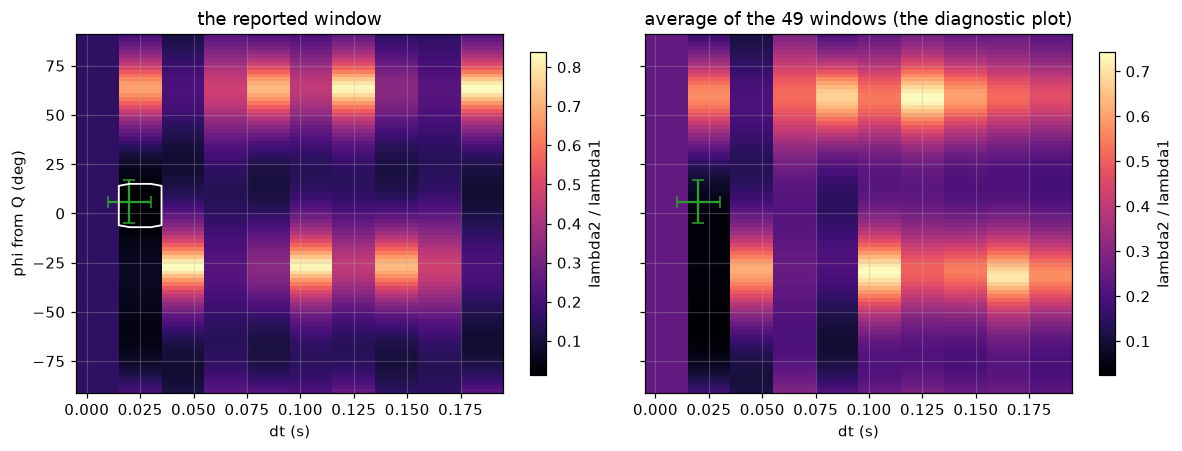

In [17]:
ALPHA = 0.003            # SWSPy's confidence level for the F-test, hard-coded in _get_phi_and_lag_errors_single_win (3 sigma)
grid = so.phi_dt_grid_best_window["STAR"]                     # lambda2 / lambda1 of the reported window: dt down, phi_Q across
lqt = m_w.stream_filtered.copy().rotate("ZNE->LQT", back_azimuth=m_w.back_azimuth, inclination=m_w.incidence_angle)
lqt.trim(s_time - so.overall_win_start_pre_fast_S_pick, s_time + so.overall_win_end_post_fast_S_pick + so.max_t_shift_s)
tr_T = lqt.select(channel="??T")[0]                           # SWSPy counts the degrees of freedom on T
dof = split_windowcheck.calc_dof(tr_T.data)
bound = split_windowcheck.ftest(grid, dof, alpha=ALPHA, k=2)
inside = grid <= bound
print(f"T trace: {tr_T.stats.npts} samples, {dof:.1f} degrees of freedom; confidence bound = {bound / grid.min():.2f} x the minimum")
print(f"inside the region: {inside.any(axis=0).sum()} phi nodes x {inside.any(axis=1).sum()} dt rows "
      f"(dt {so.lags_labels[inside.any(axis=1)]} s)")
print("SWSPy's (phi_err, dt_err) for this surface:", so._get_phi_and_lag_errors_single_win(grid, so.lags_labels, so.phis_labels, tr_T),
      "; reported:", (m_w.phi_error, m_w.dt_error))
print(f"rows 0 and 1 of the grid identical: {np.array_equal(grid[0], grid[1])}; rows 2 and 3: {np.array_equal(grid[2], grid[3])}")

phi_Q_rep = so.sws_result_df.phi_from_Q.iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, surf, title in [(axes[0], grid, "the reported window"), (axes[1], so.phi_dt_grid_average["STAR"], "average of the 49 windows (the diagnostic plot)")]:
    pc = ax.pcolormesh(so.lags_labels, so.phis_labels, surf.T, cmap="magma", shading="nearest")
    ax.errorbar(m_w.dt, phi_Q_rep, xerr=m_w.dt_error, yerr=m_w.phi_error, color="tab:green", capsize=4, lw=1.5)
    ax.set(xlabel="dt (s)", title=title)
    fig.colorbar(pc, ax=ax, label="lambda2 / lambda1", shrink=0.9)
axes[0].contour(so.lags_labels, so.phis_labels, inside.T.astype(float), levels=[0.5], colors="w", linewidths=1.2)
axes[0].set_ylabel("phi from Q (deg)")
plt.tight_layout()
good_o = quality.post_filtered(res_o)
print(f"filtered STAR events (corrected): dt_error at its floor of {good_o.dt_error.min()} s for {(good_o.dt_error == good_o.dt_error.min()).sum()} "
      f"of {len(good_o)}; phi_error {good_o.phi_error.min():.0f} to {good_o.phi_error.max():.0f} deg, median {good_o.phi_error.median():.1f}")

For this event the T trace holds 17 degrees of freedom in its 56 samples, and the bound is 2.1 times the minimum. The region (white contour, left) covers 11 phi nodes, 22 degrees, so phi_error = 11, and one pair of identical dt rows (0.02 and 0.03 s), so dt_error = 0.01. SWSPy's own error function on this surface returns the same two numbers, which checks the recipe. In the figure the identical pairs of rows show up as columns 0.02 s wide.

Two **grid floors** follow from the steps. The dt rows come in identical pairs, so dt_error is a multiple of 0.01 s and never smaller than 0.01; phi_error is a whole number of degrees. 165 of the 194 filtered corrected events sit at the dt_error floor (their phi_error runs from 5 to 20 degrees, median 11.5): for them dt_error describes the grid, not the event.

And a limit of meaning: the F-test is computed for one window. It says how well that window's surface pins down its own minimum; it knows nothing about the other 48 windows, 33 of which put the minimum 60 degrees away. The scatter between windows, Q_w and the perturbation test of the README are the checks the formal errors cannot make.

The right panel is the surface the diagnostic plot draws: λ2/λ1 averaged over all 49 windows. At dt = 0.02 s it is low over most of the phi range, from -90 to about +20 degrees from Q, and the reported cross sits at the upper end of that trough. A trough that runs along phi at a small delay is what notebook 04's null looked like: averaged over the windows, the data barely constrain phi at all.

## 9. Reading the diagnostic plot

SWSPy's standard figure packs the whole measurement into one picture. (The local copy's `plot()` is a poster-sized variant; `plot_orig()` is the standard figure.) This is the corrected measurement. After sections 5 to 8 every panel has a meaning; the table below the figure goes through them and maps each onto notebook 04's description of the AXEC2 figures.

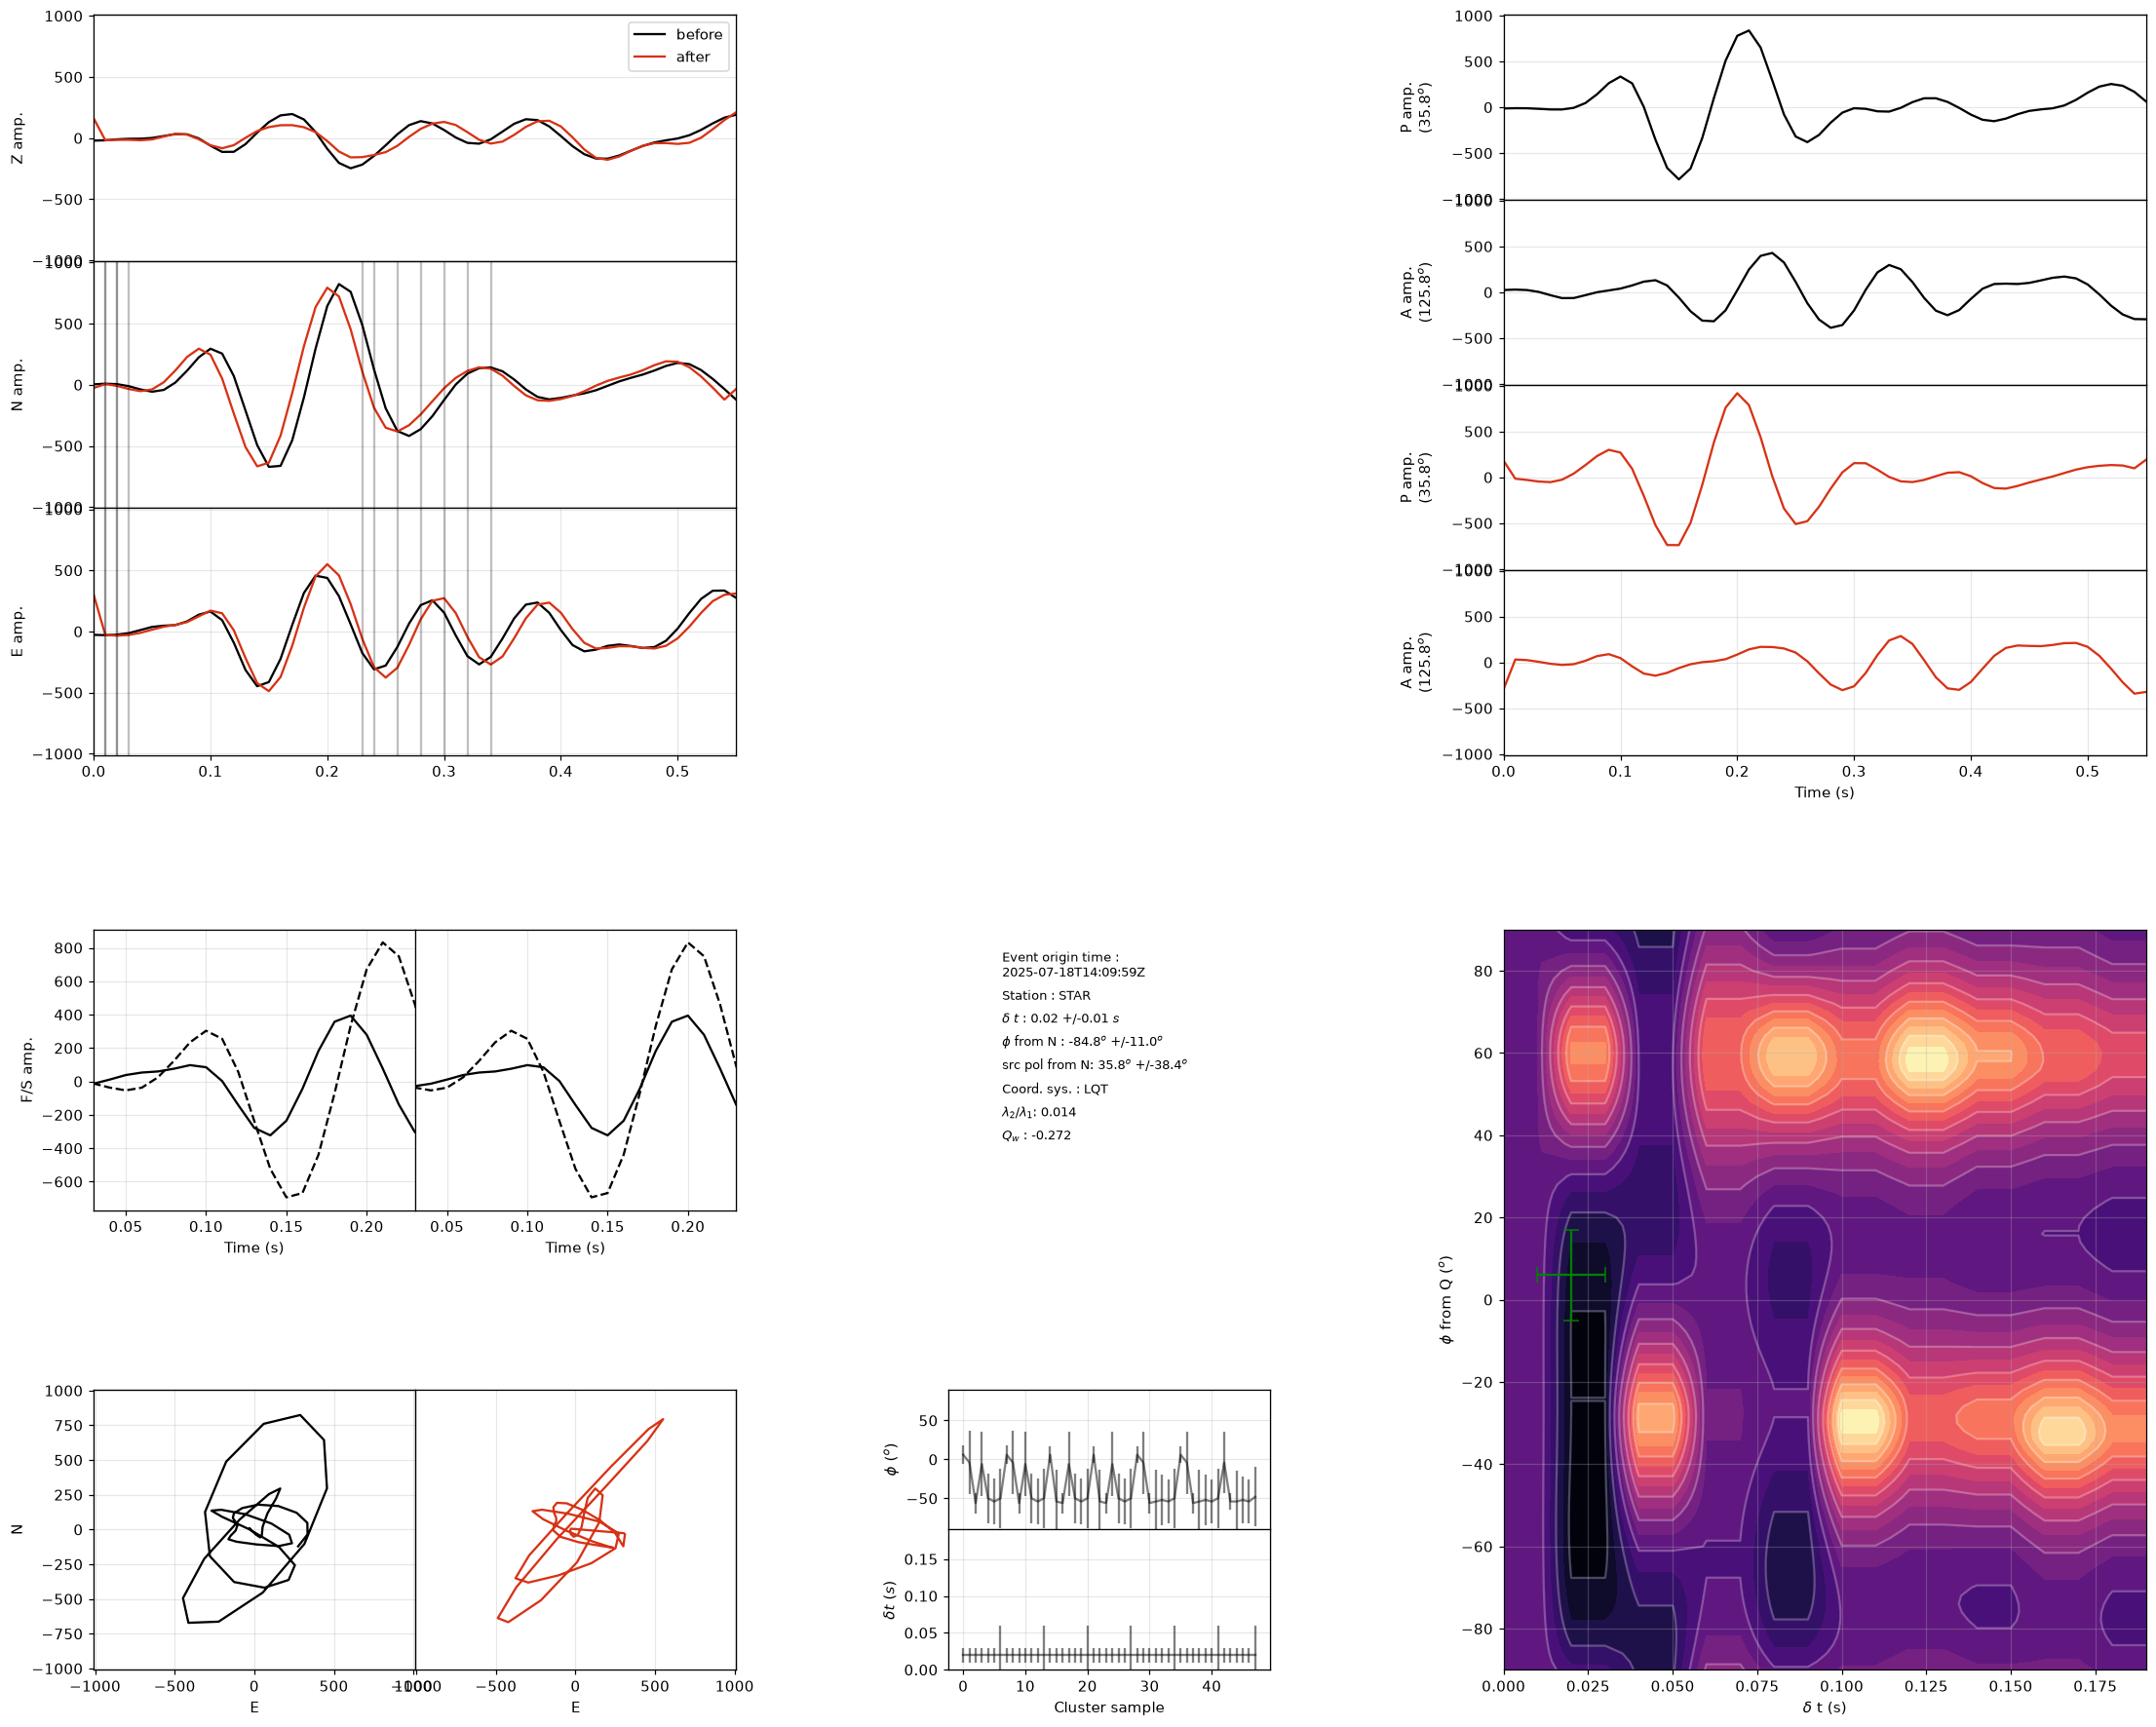

In [18]:
m_fixed.splitting_object.plot_orig(suppress_direct_plotting=False)

| where | panel | what it shows | what to look for | in notebook 04's AXEC2 figures |
| --- | --- | --- | --- | --- |
| top left | Z, N, E amp. | the filtered traces in SWSPy's cut, from 0.06 s before the S pick to 0.2 s after the last window end: before (black) and after (red) removing the split | the grey lines on N and E are the window starts (only 4 different ones, at the far left) and the 7 ends | the components with picks and analysis windows |
| top right | P and A amp. | the horizontal motion along (P) and across (A) the source polarization, 35.8 degrees here: before correction (upper pair) and after (lower pair). These P and A are not the P wave | after a good correction A is nearly flat: all the motion is along the source polarization | not shown |
| middle left | F/S amp. | the fast (solid) and slow (dashed) components over the shortest window, before and after shifting them by dt | after the shift the two have the same shape and line up | not shown |
| middle | text | dt and phi from N with their formal errors (section 8); `src pol from N` (the source polarization) and its error; the coordinate system; λ2/λ1 at the chosen minimum; Q_w | "Event origin time" is the trace start (14:09:59), not the origin (14:10:04.07): SWSPy labels the start of the stream it was given | the numbers in the captions |
| bottom left | particle motion, N against E | the horizontal motion before (black) and after (red) correction | an ellipse before that becomes a straight line after | original and corrected particle motion (drawn there as Q against T) |
| bottom middle | cluster | phi (from Q, top) and dt (bottom) of each window in each cluster, with formal error bars; noise windows are not drawn | one flat band means the windows agree | DBSCAN clustering |
| right | phi from Q against dt | λ2/λ1 averaged over the 49 windows (section 8); green cross: the reported (dt, phi_Q) with its formal errors | one small closed minimum with the cross on it, well short of the cycle-skip limit (not drawn here) | the phi-dt parameter space |

What this plot says about this event, now that you can read it:

- The traces before and after correction are nearly the same, and so are the F and S traces before and after the shift: a correction of 0.02 s moves each component by one sample.
- The correction does not straighten the motion. A keeps much of its energy after correction, and the corrected particle motion (bottom left, red) is still a loop, not a line.
- The cluster panel zig-zags between about 0 and -50 degrees from Q: the two families of section 7 inside one cluster.
- The surface has the long trough of section 8 at dt = 0.02 s, with the cross at one end of it.
- The source polarization is 35.8 degrees, with an error of 38: it lies along the north-north-east family of windows (33 to 41 degrees).

Read together, this looks like a near-null: an S wave polarized close to the north-north-east direction, carrying a delay no larger than the smallest step of the grid, so that phi is barely constrained and the windows cannot agree on it. The answers at the other incidence angles of section 6, 25 to 37 degrees, also lie along the source polarization, yet three of them have Q_w above 0.9: Q_w alone would not flag them, which is why the source-polarization screen (section 3) is a separate check. It is a hypothesis, not a measurement (the source polarization is itself poorly determined here), but it is the useful lesson of the figure-3 event: a precise-looking number can come out of a measurement with little to measure. Exercise 4 asks how common such near-nulls are among the filtered events.

## 10. Glossary

| term | meaning | section |
| --- | --- | --- |
| analysis window | one choice of start and end of the S-wave segment SWSPy measures; 49 per event | 7 |
| artifact check | phi within 20 degrees of the back azimuth or its perpendicular: a sign of a measurement artifact | 3 |
| back azimuth | direction from the station to the epicentre, degrees clockwise from north | 5 |
| choice rule | SWSPy's way to pick one answer: the tightest cluster, then the window with the smallest phi_err² + dt_err² (first on a tie) | 7 |
| cluster, core point, noise (DBSCAN) | points with at least `cluster_min_samples` neighbours within `cluster_eps` are core points; chained core points and their neighbours form a cluster; the rest are noise | 7 |
| confidence region | the (phi, dt) grid points that fit nearly as well as the best one, by an F-test | 8 |
| covariance matrix | how much each pair of components varies together; its eigenvectors are the main directions of motion | 5 |
| critical angle | arcsin(Vs / Vp), about 35 degrees: beyond it the free surface distorts S waves | 5 |
| cross-correlation method (XC) | the (phi, dt) at which the corrected fast and slow waves look most alike; SWSPy's check | 7 |
| DBSCAN | density-based clustering (Ester et al., 1996); needs no number of clusters in advance | 7 |
| degrees of freedom | the number of independent values a noisy trace holds; fewer than its samples | 8 |
| eigenvalue method (EV) | the (phi, dt) that makes the corrected particle motion most linear (smallest λ2/λ1) | 7 |
| F-test | the statistical test that sets the confidence region | 8 |
| formal error | an error bar from the shape of one misfit surface, not from repeating the measurement | 3, 8 |
| grid floor | the smallest error the grid allows: 0.01 s for dt_error | 8 |
| grid search | trying every (phi, dt) on a grid: 91 directions x 20 delays here, 10 of them distinct | 7 |
| incidence angle | angle between the incoming ray and the vertical | 5 |
| Jurkevics method | P-wave direction and rectilinearity from the eigenvectors of the 3-component covariance matrix (Jurkevics, 1988) | 5 |
| LQT (L, Q, T) | components rotated into the ray's frame: L along the ray, Q across it in the vertical plane, T horizontal and across it | 5 |
| null | an S wave that arrives unsplit because it already shook along or across the fast axis; phi then lines up with the source polarization | 3 |
| particle motion | the path the ground follows, one component plotted against another | 5 |
| percent anisotropy | 100 dt / S travel time along the ray | 1 |
| phi from Q, phi from N | the fast direction measured from Q (SWSPy's frame) or from north; phi = back azimuth + phi_Q | 5 |
| Q_w | Wüstefeld et al. (2010) quality score, from -1 (null) to 1 (good split), comparing EV and XC | 8 |
| radial (R) | horizontal direction along the line from the epicentre, pointing away from it | 5 |
| rectilinearity | 1 - (λ2 + λ3) / (2 λ1): 1 for motion along a line | 5 |
| rho, dphi | dt_XC / dt_EV and phi_EV - phi_XC: the two coordinates of the Wüstefeld plane | 8 |
| shear-wave window | the cone of incidence angles inside which S waves reach the surface undistorted | 5 |
| source polarization (`src_pol`) | the direction the S wave shook the ground before it split | 3 |
| spy | a wrapper that records a function's inputs and outputs without changing what it does | 7 |
| Tmid | SWSPy's dominant period of the S wave, which sizes the window ends | 7 |
| 3 sigma | a confidence level of 99.7 percent (α = 0.003), SWSPy's choice for the F-test | 8 |

References in this notebook: Hudson, T.S., Asplet, J. & Walker, A.M. (2023), *Automated shear-wave splitting analysis for single- and multi-layer anisotropic media*, Seismica 2(2), doi:10.26443/seismica.v2i2.1031. Silver, P.G. & Chan, W.W. (1991), *Shear wave splitting and subcontinental mantle deformation*, JGR 96, 16429-16454. Jurkevics, A. (1988), *Polarization analysis of three-component array data*, BSSA 78, 1725-1743. Teanby, N.A., Kendall, J.-M. & van der Baan, M. (2004), *Automation of shear-wave splitting measurements using cluster analysis*, BSSA 94, 453-463. Ester, M., Kriegel, H.-P., Sander, J. & Xu, X. (1996), *A density-based algorithm for discovering clusters in large spatial databases with noise*, Proc. KDD-96, 226-231. Wüstefeld, A. & Bokelmann, G. (2007), *Null detection in shear-wave splitting measurements*, BSSA 97, 1204-1211. Wüstefeld, A., Al-Harrasi, O., Verdon, J.P., Wookey, J. & Kendall, J.-M. (2010), *A strategy for automated analysis of passive microseismic data to image seismic anisotropy and fracture characteristics*, Geophys. Prospect. 58, 755-773. Walsh, E., Arnold, R. & Savage, M.K. (2013), *Silver and Chan revisited*, JGR Solid Earth 118, 5500-5515. Booth, D.C. & Crampin, S. (1985), *Shear-wave polarizations on a curved wavefront at an isotropic free surface*, Geophys. J. R. astr. Soc. 83, 31-45. Svenningsen, L. & Jacobsen, B.H. (2007), *Absolute S-velocity estimation from receiver functions*, GJI 170, 1089-1094.

## 11. Exercises

Each one asks a question the project needs answered. Together they take about an hour and about six minutes of computing; the slowest cell runs for about two minutes.

1. **Is the published table replicable?** Use `measure.remeasure` to re-measure every row of both STAR files: the archived one on the components as labelled and without the clip gate, which the archived run did not have (`correct_orientation=False, gates=quality.PreGates(clip_fraction_max=np.inf)`), and the corrected one as it is. For the rows each file measured, how many reproduce in all eight numbers of section 2, how many differ in Q_w only, and how many in phi or dt? How many events enter or leave the filtered set?
2. **Is a fast direction set by the data or by the window-selection rule?** Section 7 found an event whose answer came from a tie inside a cluster that held two families of directions. For each of the 194 filtered corrected events, record the windows (`record_windows`), find the cluster SWSPy chose, and measure its spread (the largest axial difference between two of its fast directions) and the fraction of its windows within 20 degrees of the answer. How many events are like the figure-3 event?
3. **How much do the fast directions depend on the velocity model?** The ray-traced incidence angles come from a velocity model, and section 5 showed that the data do not confirm them. Re-measure the 194 filtered events with every incidence angle 5 degrees smaller and 5 degrees larger (`good.assign(incidence_angle=...)` and `measure.remeasure`). How many keep their fast direction within 20 degrees? How many still pass the filter? Does the station's mean fast direction move by more than its bootstrap interval?
4. **Is the north-north-east cluster a polarization artifact?** A null lines phi up with the source polarization, not with the back azimuth. Using `src_pol` from exercise 1's corrected re-run, count the filtered events whose phi is within 20 degrees of `src_pol` or of its perpendicular (`stats.near_axis`), and compare with the same count against the back azimuth (the artifact check) and with chance (`stats.chance_near_axis`). Does removing the near-nulls move the mean fast direction?
5. **What does the SNR gate cost the corrected rose?** Nine corrected STAR events stopped at the SNR gate. Re-measure them with `PreGates.snr_min` halved. How many get a measurement? How many pass the post-processing filter as it is, and with `PostFilter.snr_min` halved too? Where do their fast directions fall?
6. **Planning week 8.** Time 20 measurements and take the median. How long would one pass over all nine stations' results files take, and a 10-value sweep of one processing parameter? Why the median rather than the mean?

Next: `06_exploring_the_results.ipynb`.

## 12. Example solutions

One way to do each exercise. Try them yourself first. The slow ones say how long they run.

### Exercise 1: is the published table replicable?

`measure.remeasure` re-runs a whole results table with its stored incidence angles and returns one row per input row, in the same order. Compare the eight numbers of section 2 for the rows the file measured, and the filtered sets. Each run takes about two minutes on a laptop.

In [19]:
cols = ["filter_band", "snr_horizontal", "phi", "dt", "phi_error", "dt_error", "quality", "dominant_period"]

def compare(old, new):
    """For the rows the old table measured (stage ok): which of the eight numbers reproduce (to 1e-6)."""
    ok = old.stage == "ok"
    same = pd.DataFrame({c: (old[c].astype(str) == new[c].astype(str)) if c == "filter_band"
                         else np.isclose(old[c].astype(float), new[c].astype(float), atol=1e-6, equal_nan=True)
                         for c in cols}, index=old.index)[ok]
    identical = same.all(axis=1)
    qw_only = ~same.quality & same.drop(columns="quality").all(axis=1)
    phi_dt = ~(same.phi & same.dt)
    f_old, f_new = quality.post_filter_mask(old), quality.post_filter_mask(new)
    return pd.Series({"measured rows": int(ok.sum()), "identical": int(identical.sum()), "differ in Q_w only": int(qw_only.sum()),
                      "differ in phi or dt": int(phi_dt.sum()), "  of which no longer measured": int((new.stage[ok] != "ok").sum()),
                      "stage changed (any row)": int((old.stage != new.stage).sum()),
                      "filtered: file": int(f_old.sum()), "filtered: here": int(f_new.sum()),
                      "filtered: in both": int((f_old & f_new).sum()), "filtered: out": int((f_old & ~f_new).sum()),
                      "filtered: in": int((~f_old & f_new).sum())})

redo_a = measure.remeasure(ref, "STAR", correct_orientation=False, gates=quality.PreGates(clip_fraction_max=np.inf))
print(f"archived file: {len(ref)} rows re-measured")

archived file: 903 rows re-measured


In [20]:
redo_o = measure.remeasure(res_o, "STAR")
print(f"corrected file: {len(res_o)} rows ({(res_o.stage != 'missing_channel').sum()} with waveforms) re-measured")
pd.DataFrame({"archived (labelled channels)": compare(ref, redo_a), "corrected (oriented file)": compare(res_o, redo_o)})

corrected file: 1196 rows (901 with waveforms) re-measured


,archived (labelled channels),corrected (oriented file)
measured rows,709,659
identical,642,626
differ in Q_w only,53,23
differ in phi or dt,14,10
of which no longer measured,4,0
stage changed (any row),8,0
filtered: file,110,194
filtered: here,114,196
filtered: in both,108,193
filtered: out,2,1


Both files reproduce well, and neither perfectly:

- **Archived file** (labelled channels): of the 709 rows Michael's run measured, 642 (91 percent) reproduce in all eight numbers, 53 differ in Q_w only, and 14 differ in phi or dt, 4 of them because they are not measured at all here. Eight rows change stage, three of them from `fail_no_result` to measured. The filtered set has 110 events in the file and 114 here, 108 of them in both: 2 drop out and 6 come in.
- **Corrected file**: of 659 measured rows, 626 (95 percent) reproduce in all eight numbers, 23 differ in Q_w only and 10 in phi or dt; no row changes stage. The filtered set has 194 events in the file and 196 here, 193 in both: 1 out and 3 in.

So the published tables are replicable where it matters most, the same events and the same numbers for 91 to 95 percent of the rows, but the filtered set moves by a few events (4 to 8) with the computing environment alone. The corrected file reproduces better, probably because it was computed recently with software closer to this environment's. For the project: treat the filtered count as uncertain by a few events, record the environment (package versions) with every results file, and always include Q_w in a reproduction check, because most of the differences are there.

### Exercise 2: is a fast direction set by the data or by the window-selection rule?

The spy of section 7 records two calls per event, EV then XC; the EV call of each event is the first one made after it starts. About 35 s.

In [21]:
good = quality.post_filtered(res_o)
cat_by_evid = cat.set_index("evid")
rows = []
with record_windows() as calls_f:
    for _, t in good.iterrows():
        r = cat_by_evid.loc[t.evid].copy(); r["evid"] = t.evid
        st = data.get_event_stream("STAR", r, allow_download=False)
        n_before = len(calls_f)
        mm = measure.measure_event(r, st, "STAR", lat, lon, incidence_angle=t.incidence_angle)
        w = calls_f[n_before]["windows"]                              # this event's eigenvalue answers
        ci_ = mm.splitting_object.clustering_info["STAR"]
        mem = ci_["clusters_dict"][str(ci_["min_var_idx"])]["sample_idxs"]
        ans = mm.splitting_object.sws_result_df.phi_from_Q.iloc[0]
        phis = w.phi_Q.values[mem]
        rows.append({"evid": t.evid, "phi": measure.phi_0_180(mm.phi), "same as file": bool(np.isclose(mm.phi, t.phi)),
                     "windows in cluster": len(mem), "clusters": len(ci_["clusters_dict"]),
                     "cluster spread": float(stats.axial_diff(phis[:, None], phis[None, :]).max()),
                     "cluster agreeing with answer": float(np.mean(stats.axial_diff(phis, ans) <= 20)),
                     "windows agreeing with answer": float(np.mean(stats.axial_diff(w.phi_Q, ans) <= 20)),
                     "lone window at the largest dt": bool((w.dt == w.dt.max()).sum() == 1), "Q_w here": mm.quality})
spread = pd.DataFrame(rows)
print(f"{len(spread)} filtered events; {spread['same as file'].sum()} give the file's phi here")
print(f"spread of the chosen cluster: median {spread['cluster spread'].median():.0f} deg, 90th percentile "
      f"{spread['cluster spread'].quantile(0.9):.0f}; above 30 deg: {(spread['cluster spread'] > 30).sum()}")
print(f"answer shared by fewer than half of its cluster: {(spread['cluster agreeing with answer'] < 0.5).sum()}; "
      f"by fewer than half of all 49 windows: {(spread['windows agreeing with answer'] < 0.5).sum()}")
lone = spread["lone window at the largest dt"]
print(f"events with one window alone at the largest dt: {lone.sum()}; median cluster spread {spread['cluster spread'][lone].median():.0f} deg "
      f"for them, {spread['cluster spread'][~lone].median():.0f} deg for the others")
spread.sort_values("cluster spread", ascending=False).head(5).round(2)

194 filtered events; 194 give the file's phi here
spread of the chosen cluster: median 4 deg, 90th percentile 10; above 30 deg: 2
answer shared by fewer than half of its cluster: 1; by fewer than half of all 49 windows: 4
events with one window alone at the largest dt: 20; median cluster spread 4 deg for them, 5 deg for the others


,evid,phi,same as file,windows in cluster,clusters,cluster spread,cluster agreeing with answer,windows agreeing with answer,lone window at the largest dt,Q_w here
18,62134957,44.97,True,34,1,60.0,0.74,0.80,True,0.97
13,62134697,92.05,True,48,1,56.0,0.35,0.35,True,0.31
12,62134647,49.20,True,29,1,30.0,1.00,0.82,False,0.97
35,62136112,25.64,True,40,1,22.0,0.90,0.76,False,0.87
174,62146137,33.67,True,49,1,20.0,1.00,1.00,False,0.94


For the filtered events the windows usually agree closely. The median spread of the chosen cluster is 4 degrees and the 90th percentile 10; only 2 of the 194 clusters span more than 30 degrees. The answer is shared by fewer than half of its own cluster for 1 event, and by fewer than half of all 49 windows for 4.

The two wide clusters are the figure-3 pattern. Both have one window alone at the largest dt, which shrinks every other window towards the centre of DBSCAN's plane. 62134957 (spread 60 degrees) still reports the majority answer, 45 degrees, shared by 74 percent of its cluster. 62134697 (spread 56 degrees) reports 92 degrees, east-west, shared by only 35 percent of its cluster: the same failure as the figure-3 event. It also has Q_w 0.31 here, below the cut, so it is very likely the one filtered event of the corrected file that drops out in exercise 1.

A lone window at the largest dt is common, 20 of the 194 events, and harmless on its own: those 20 have the same median spread (4 degrees) as the others (5). It does damage only when the windows also split into two families of fast directions, which happened twice here.

So, at STAR, the choice rule overrides the majority of the windows for 1 of the 194 filtered events (and for the figure-3 event, which is not in the filtered set), and both times the result is an east-west answer, close to the back azimuth, that most windows do not support. Rare, but it is exactly the kind of answer the artifact check exists to catch. The weak point is SWSPy's scaling of the delays by their largest value: one window at the edge of the grid is enough to merge families of fast directions. Scaling by `max_t_shift_s` instead would avoid it; that is a change for the research pipeline (and for SWSPy), not something to patch in a lesson.

### Exercise 3: how much do the fast directions depend on the velocity model?

Why 5 degrees? The filtered events' ray-traced angles span about 19 to 34 degrees, and a few degrees is the size of the bending a modest error in the near-surface velocity would cause; the P-wave estimate of section 5 is much further away, so this is a gentle test. Two runs of `remeasure` on 194 events, about a minute.

In [22]:
d_inc = 5                                                      # degrees; see the text
alt_runs = {d: measure.remeasure(good.assign(incidence_angle=good.incidence_angle + d), "STAR") for d in (-d_inc, d_inc)}
both = (stats.axial_diff(alt_runs[-d_inc].phi, good.phi) <= 20) & (stats.axial_diff(alt_runs[d_inc].phi, good.phi) <= 20)
in_all = good.index[quality.post_filter_mask(alt_runs[-d_inc]) & quality.post_filter_mask(alt_runs[d_inc])]
summary = {}
for d, a in [(-d_inc, alt_runs[-d_inc]), (0, good), (d_inc, alt_runs[d_inc])]:
    passed = quality.post_filtered(a)
    mean, lo, hi, _ = stats.bootstrap_axial_mean(passed.phi)
    summary[f"{d:+d} deg"] = {"measured": int((a.stage == "ok").sum()), "stopped by the gate": int((a.stage == "fail_incidence").sum()),
                             "pass the filter": len(passed), "phi within 20 deg of the baseline": int((stats.axial_diff(a.phi, good.phi) <= 20).sum()),
                             "axial mean of those passing": mean, "68% interval, low": mean + lo, "68% interval, high": mean + hi,
                             f"axial mean of the {len(in_all)} passing at all three": stats.axial_mean(a.loc[in_all, "phi"])[0]}
print(f"phi within 20 deg of the baseline at both -{d_inc} and +{d_inc} deg: {both.sum()} of {len(good)}")
pd.DataFrame(summary).round(1)

phi within 20 deg of the baseline at both -5 and +5 deg: 181 of 194


,-5 deg,+0 deg,+5 deg
measured,191.0,194.0,186.0
stopped by the gate,0.0,0.0,2.0
pass the filter,175.0,194.0,167.0
phi within 20 deg of the baseline,190.0,194.0,185.0
axial mean of those passing,35.4,33.7,32.3
"68% interval, low",34.5,32.8,31.4
"68% interval, high",36.3,34.7,33.2
axial mean of the 151 passing at all three,36.4,34.3,32.3


- **Individual fast directions are robust.** 181 of the 194 keep phi within 20 degrees of the baseline at both -5 and +5 degrees.
- **The filtered set is not.** 175 events pass the filter at -5 degrees and 167 at +5 (where 2 rays now exceed the 45-degree gate): 19 to 27 of the 194 drop out. Only these 194 were re-measured here; other events could come in, so the real change of membership is larger.
- **The mean fast direction rotates with the angle**: 35.4 degrees at -5, 33.7 at the stored angles, 32.3 at +5, each with a 68 percent bootstrap interval of about ±0.9 degrees. Among the 151 events that pass at all three angles it is 36.4, 34.3 and 32.3, so the shift comes from the measurements, not from the change of membership.

A 5-degree error in the incidence angles moves STAR's mean fast direction by 1.4 to 2.1 degrees, about twice its bootstrap half-width. The velocity model is a systematic error of the same size as the statistical one, and the bootstrap does not see it. It does not change the answer at STAR (north-north-east either way), but a difference of a couple of degrees between stations, or between periods with different ray paths, means little unless the velocity model is right at both. Section 5 suggests the stored angles could be off by much more than 5 degrees, so this test is a lower bound.

### Exercise 4: is the north-north-east cluster a polarization artifact?

`src_pol` is not in the results files, but exercise 1's re-run of the corrected file has it for every measured event.

194 filtered events; near-null against src_pol: 32 (16%); against the back azimuth: 57 (29%); both: 5; chance for a random fast axis: 44%
phi - back azimuth is a whole even number of degrees for every event: True; exactly 20 or 70 degrees: 10 events
src_pol: axial mean 53 deg, R = 0.68; its formal error: median 13 deg
axial mean phi, all (N = 194): 33.7 deg (68% bootstrap interval 32.8 to 34.7)
axial mean phi, without the src_pol near-nulls (N = 162): 33.5 deg (68% bootstrap interval 32.5 to 34.6)
axial mean phi, without the back-azimuth ones (N = 137): 35.5 deg (68% bootstrap interval 34.8 to 36.2)


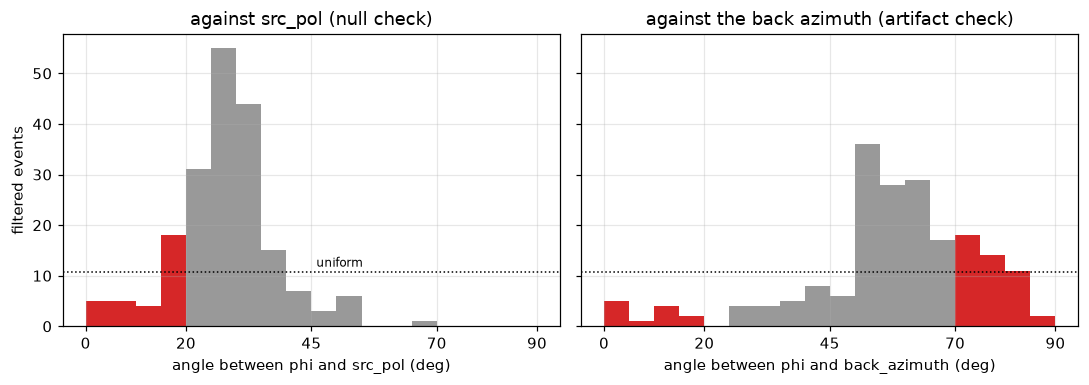

In [23]:
f = good.assign(src_pol=redo_o.loc[good.index, "src_pol"],             # the filtered events, with src_pol
               src_pol_error=redo_o.loc[good.index, "src_pol_error"])  # from exercise 1's re-run
vs_src = stats.near_axis(f.phi, f.src_pol)                    # within 20 deg of src_pol or its perpendicular
vs_baz = stats.near_axis(f.phi, f.back_azimuth)
chance = stats.chance_near_axis()
print(f"{len(f)} filtered events; near-null against src_pol: {vs_src.sum()} ({vs_src.mean():.0%}); against the back azimuth: "
      f"{vs_baz.sum()} ({vs_baz.mean():.0%}); both: {(vs_src & vs_baz).sum()}; chance for a random fast axis: {chance:.0%}")
d_baz = stats.axial_diff(f.phi, f.back_azimuth)
print(f"phi - back azimuth is a whole even number of degrees for every event: {np.allclose(np.round(d_baz) % 2, 0) and np.allclose(d_baz, np.round(d_baz))}; "
      f"exactly 20 or 70 degrees: {np.isin(np.round(d_baz, 6), [20, 70]).sum()} events")
src_mean, src_R = stats.axial_mean(f.src_pol)
print(f"src_pol: axial mean {src_mean:.0f} deg, R = {src_R:.2f}; its formal error: median {f.src_pol_error.median():.0f} deg")
for name, sel in [("all", f), ("without the src_pol near-nulls", f[~vs_src]), ("without the back-azimuth ones", f[~vs_baz])]:
    m_, lo, hi, _ = stats.bootstrap_axial_mean(sel.phi)
    print(f"axial mean phi, {name} (N = {len(sel)}): {m_:.1f} deg (68% bootstrap interval {m_ + lo:.1f} to {m_ + hi:.1f})")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
bins = np.arange(0, 91, 5)
for ax, ref_col, flag, title in [(axes[0], "src_pol", vs_src, "against src_pol (null check)"),
                                 (axes[1], "back_azimuth", vs_baz, "against the back azimuth (artifact check)")]:
    diff = stats.axial_diff(f.phi, f[ref_col])
    ax.hist(diff, bins, color="0.6")
    ax.hist(diff[flag], bins, color="tab:red")
    ax.axhline(len(f) / len(bins[:-1]), color="k", ls=":", lw=1)
    ax.set(xlabel=f"angle between phi and {ref_col} (deg)", title=title, xticks=[0, 20, 45, 70, 90])
axes[0].set_ylabel("filtered events"); axes[0].text(46, len(f) / 18 + 1, "uniform", fontsize=8)
plt.tight_layout()

- **Against src_pol** (the null check): 32 of the 194 filtered events (16 percent) have phi within 20 degrees of the source polarization or its perpendicular, far fewer than the 44 percent a random fast axis would give. The left histogram shows why: most fast directions lie 20 to 40 degrees from the source polarization. Part of that is selection, because near-nulls tend to fail the Q_w cut before this screen sees them.
- **Against the back azimuth** (the artifact check): 57 (29 percent), also below chance, and only 5 events are flagged by both. The two screens pick out different events, so they are not interchangeable.
- **The mean does not move.** 33.7 degrees for all 194 (68 percent interval 32.8 to 34.7), 33.5 (32.5 to 34.6) without the 32 src_pol near-nulls. Without the 57 back-azimuth ones it is 35.5 (34.8 to 36.2): those include fast axes near 0 and near 90 degrees, so removing them nudges the mean but leaves it north-north-east.

So the north-north-east cluster is not a polarization artifact: fast directions avoid the source polarization rather than follow it. The source polarizations themselves are not random either (axial mean 53 degrees, R = 0.68), as expected for a swarm of similar earthquakes on similar paths, so a wider set of polarizations (other stations, other earthquakes) would test this more strongly. Two caveats: SWSPy computes `src_pol` *after* removing the measured split, so it is not independent of phi, and its formal error has a median of 13 degrees.

One detail in the right panel: phi - back azimuth is always a whole even number of degrees (phi = back azimuth + phi_Q, and phi_Q is on the 2-degree grid), so 10 events sit exactly at 20 or 70 degrees, on the edge of the screen. Whether they count depends on the last digit of a floating-point number, which is why this count can come out a few events different in other environments.

### Exercise 5: what does the SNR gate cost the corrected rose?

`dataclasses.replace` makes a copy of the default gates with one value changed, so no threshold is typed in.

In [24]:
from dataclasses import replace
low_snr = res_o[res_o.stage == "fail_snr"]
lower_pre = replace(quality.DEFAULT_PRE, snr_min=quality.DEFAULT_PRE.snr_min / 2)
lower_post = replace(quality.DEFAULT_POST, snr_min=quality.DEFAULT_POST.snr_min / 2)
redo_snr = measure.remeasure(low_snr, "STAR", gates=lower_pre)
table = redo_snr[["evid", "snr_horizontal", "stage", "phi", "dt", "dominant_period", "phi_error", "dt_error", "quality"]].copy()
table["phi"] = measure.phi_0_180(table.phi)
table["passes the filter"] = quality.post_filter_mask(redo_snr)
table["passes with PostFilter.snr_min halved too"] = quality.post_filter_mask(redo_snr, lower_post)
print(f"{len(low_snr)} corrected STAR events stopped at the SNR gate ({quality.DEFAULT_PRE.snr_min}); "
      f"their SNR {low_snr.snr_horizontal.min():.2f} to {low_snr.snr_horizontal.max():.2f}")
table.round(2)

9 corrected STAR events stopped at the SNR gate (2.0); their SNR 1.43 to 1.91


,evid,snr_horizontal,stage,phi,dt,dominant_period,phi_error,dt_error,quality,passes the filter,passes with PostFilter.snr_min halved too
139,62134632,1.70,fail_no_result,NaN,NaN,NaN,NaN,NaN,NaN,False,False
227,62135297,1.86,ok,174.77,0.02,0.10,21.0,0.01,0.00,False,False
368,62136497,1.87,ok,85.81,0.10,0.14,50.0,0.05,-0.80,False,False
414,62137007,1.43,ok,107.28,0.14,0.18,8.0,0.01,0.00,False,False
484,62138087,1.91,ok,47.36,0.02,0.15,12.0,0.01,-0.58,False,False
589,62139492,NaN,fail_snr,NaN,NaN,NaN,NaN,NaN,NaN,False,False
672,62140432,1.57,fail_no_result,NaN,NaN,NaN,NaN,NaN,NaN,False,False
756,62141392,1.87,ok,19.83,0.08,0.21,67.0,0.09,0.91,False,False
1033,62145982,1.49,ok,46.44,0.10,0.13,14.0,0.01,0.94,False,False


With the gate halved, 6 of the 9 events get a measurement. Two end in `fail_no_result` (SWSPy found no cluster of windows), and 62139492 still stops at the gate: the filter bank found no usable band, so it has no SNR at all.

None of the 6 passes the post-processing filter, as it is or with `PostFilter.snr_min` halved too. Four fail on Q_w (0, -0.80, 0 and -0.58), and two of those on phi_error as well; 62141392 has Q_w 0.91 but phi_error 67 degrees and dt_error 0.09 s; 62145982, once the SNR cut is halved, passes every cut except dt ≤ T/2: its dt of 0.10 s is more than half its dominant period of 0.13 s. Their fast directions scatter from 20 to 175 degrees.

So the SNR gate costs the corrected rose nothing: none of the 9 would enter it, even with both SNR cuts halved. At STAR the gate stops 9 of the 901 events with waveforms (1 percent), and the other cuts already reject what lies just below it. Notebook 03 (exercise 2) explains why this SNR hardly matters here: it compares S with the P coda, not with the background noise.

### Exercise 6: planning week 8

The median, because a few measurements are much slower than the rest: the first of a session (numba compiles the grid search) and any that run while the computer is busy with something else.

In [25]:
import time
seconds = []
for _, t in quality.successful(res_o).sample(20, random_state=0).iterrows():
    r = cat_by_evid.loc[t.evid].copy(); r["evid"] = t.evid
    st = data.get_event_stream("STAR", r, allow_download=False)
    t0 = time.perf_counter()
    measure.measure_event(r, st, "STAR", lat, lon, incidence_angle=t.incidence_angle)
    seconds.append(time.perf_counter() - t0)
per_event = float(np.median(seconds))
print(f"one measurement: median {per_event:.2f} s (range {min(seconds):.2f} to {max(seconds):.2f} s over {len(seconds)} events)")
rows_per_station = {f.name.split("_")[1].upper(): len(pd.read_csv(f)) for f in sorted(paths.RESULTS.glob("sws_*_strict_results.csv"))}
total = sum(rows_per_station.values())
print("rows per station (strict results files):", rows_per_station)
print(f"one pass over all {len(rows_per_station)} stations ({total} rows): at most about {total * per_event / 60:.0f} min")
print(f"a 10-value sweep of one processing parameter: at most about {10 * total * per_event / 3600:.1f} h")

one measurement: median 0.07 s (range 0.06 to 0.07 s over 20 events)
rows per station (strict results files): {'COPP': 348, 'LON': 1172, 'MILD': 685, 'OBSR': 139, 'PANH': 414, 'PARA': 749, 'RCM': 509, 'RER': 450, 'STAR': 903}
one pass over all 9 stations (5369 rows): at most about 6 min
a 10-value sweep of one processing parameter: at most about 1.0 h


A measurement takes about 0.07 s on the machine that ran this notebook (median of 20; expect up to two or three times that on a laptop doing other things). The nine stations' results files hold 5369 rows, so one pass over all of them takes at most about 6 minutes and a 10-value sweep of one processing parameter at most about an hour. These are upper bounds: rows without waveforms, or stopped by an early gate (most rows at PANH, OBSR, PARA, RER and COPP stop at the incidence gate), take a fraction of the time.

That is fine for a script that runs over lunch, and too slow for a notebook cell. Two more reasons to put the week-8 benchmark in a script:

- In a notebook a measurement can be several times slower than in a script. SWSPy calls Python's garbage collector twice per measurement, and each call has to look at every object the notebook holds; that is what the `gc.freeze()` of section 8 avoids (it tells the collector to skip the objects that already exist).
- Only *processing* parameters (windows, pick uncertainty, incidence angle, filter bank) need the pipeline re-run. Sweeping the *post-processing* thresholds (Q_w, errors, SNR) needs no re-measurement at all, because they only filter rows that already exist; notebook 07 does those sweeps on the results table in milliseconds.